# Projeto 2: previsão da nota de Matemática do ENEM 2023

**Alvo (y):** `NU_NOTA_MT`. **Tarefa:** regressão. **Dados:** microdados do Inep, 3.933.955 participantes.

Este notebook vai da base bruta até os datasets 1, 1 + features, 2 e 2 + features, salvos em `dados/processed/`.
Rode de cima para baixo (Run All, leva alguns minutos por causa da leitura do CSV e dos `rank()`).

| Seção | O que faz |
|---|---|
| 1 | Carrega a base bruta |
| 2 | Triagem: o que falta em cada coluna |
| 3 | Dicionário: o que cada coluna é e se pode ser feature |
| 4 | Remove candidatas com mais de 50% de null |
| 5 | Remove linhas sem nota de Matemática e guarda os IDs |
| 6 | Monta o `df_modelo` (features + alvo) |
| 7 | Versão numérica (`df_num`), com letras do questionário em números |
| 7b | Exploração por sexo e língua: quem faz mais o Enem e quem tira notas maiores |
| 8 | Spearman das colunas com a nota |
| 9 | Colunas redundantes e fusão (`df_fundido`) |
| 10 | Spearman depois do tratamento |
| 11 | Salva o dataset 1 |
| 11b | Dataset 1 revisado (sem nacionalidade, tipo de escola e colunas "não sei"), substitui o arquivo salvo |
| 11c | Dataset 1 + features (3 colunas criadas, Spearman e arquivo `dataset_1_features.csv`) |
| 12 | Dataset 2 (dataset 1 + escola) e dataset 2 + features, sem as colunas `DEP_*`, salvos em `dataset_2_escola.csv` e `dataset_2_features_escola.csv` |

**Regras:** nota ausente não vira zero; nenhuma nota, resposta ou gabarito entra em X; a divisão 80/20 ainda não foi feita.

In [307]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

## 1. Carga dos dados

Lê o CSV bruto (separador `;`, codificação latin-1). Esperado: `(3933955, 76)`.

In [308]:
df = pd.read_csv("../dados/raw/DADOS/MICRODADOS_ENEM_2023.csv", sep=";", encoding="latin-1")
df.shape

(3933955, 76)

## 2. Triagem: o que falta em cada coluna

`null` (NaN no pandas) é valor vazio. As colunas da escola têm 75,6% de null e `TP_ENSINO` tem 66,0%.
As colunas de nota e prova têm 31,6% ou 28,2% de null porque a pessoa faltou ou foi eliminada.

In [309]:
df.columns

Index(['NU_INSCRICAO', 'NU_ANO', 'TP_FAIXA_ETARIA', 'TP_SEXO', 'TP_ESTADO_CIVIL', 'TP_COR_RACA', 'TP_NACIONALIDADE', 'TP_ST_CONCLUSAO', 'TP_ANO_CONCLUIU', 'TP_ESCOLA', 'TP_ENSINO', 'IN_TREINEIRO',
       'CO_MUNICIPIO_ESC', 'NO_MUNICIPIO_ESC', 'CO_UF_ESC', 'SG_UF_ESC', 'TP_DEPENDENCIA_ADM_ESC', 'TP_LOCALIZACAO_ESC', 'TP_SIT_FUNC_ESC', 'CO_MUNICIPIO_PROVA', 'NO_MUNICIPIO_PROVA', 'CO_UF_PROVA',
       'SG_UF_PROVA', 'TP_PRESENCA_CN', 'TP_PRESENCA_CH', 'TP_PRESENCA_LC', 'TP_PRESENCA_MT', 'CO_PROVA_CN', 'CO_PROVA_CH', 'CO_PROVA_LC', 'CO_PROVA_MT', 'NU_NOTA_CN', 'NU_NOTA_CH', 'NU_NOTA_LC',
       'NU_NOTA_MT', 'TX_RESPOSTAS_CN', 'TX_RESPOSTAS_CH', 'TX_RESPOSTAS_LC', 'TX_RESPOSTAS_MT', 'TP_LINGUA', 'TX_GABARITO_CN', 'TX_GABARITO_CH', 'TX_GABARITO_LC', 'TX_GABARITO_MT',
       'TP_STATUS_REDACAO', 'NU_NOTA_COMP1', 'NU_NOTA_COMP2', 'NU_NOTA_COMP3', 'NU_NOTA_COMP4', 'NU_NOTA_COMP5', 'NU_NOTA_REDACAO', 'Q001', 'Q002', 'Q003', 'Q004', 'Q005', 'Q006', 'Q007', 'Q008',
       'Q009', 'Q010', 'Q011',

In [310]:
df.head()

,NU_INSCRICAO,NU_ANO,TP_FAIXA_ETARIA,TP_SEXO,TP_ESTADO_CIVIL,TP_COR_RACA,TP_NACIONALIDADE,TP_ST_CONCLUSAO,TP_ANO_CONCLUIU,TP_ESCOLA,TP_ENSINO,IN_TREINEIRO,CO_MUNICIPIO_ESC,NO_MUNICIPIO_ESC,CO_UF_ESC,SG_UF_ESC,TP_DEPENDENCIA_ADM_ESC,TP_LOCALIZACAO_ESC,TP_SIT_FUNC_ESC,CO_MUNICIPIO_PROVA,NO_MUNICIPIO_PROVA,CO_UF_PROVA,SG_UF_PROVA,TP_PRESENCA_CN,TP_PRESENCA_CH,TP_PRESENCA_LC,TP_PRESENCA_MT,CO_PROVA_CN,CO_PROVA_CH,CO_PROVA_LC,CO_PROVA_MT,NU_NOTA_CN,NU_NOTA_CH,NU_NOTA_LC,NU_NOTA_MT,TX_RESPOSTAS_CN,TX_RESPOSTAS_CH,TX_RESPOSTAS_LC,TX_RESPOSTAS_MT,TP_LINGUA,TX_GABARITO_CN,TX_GABARITO_CH,TX_GABARITO_LC,TX_GABARITO_MT,TP_STATUS_REDACAO,NU_NOTA_COMP1,NU_NOTA_COMP2,NU_NOTA_COMP3,NU_NOTA_COMP4,NU_NOTA_COMP5,NU_NOTA_REDACAO,Q001,Q002,Q003,Q004,Q005,Q006,Q007,Q008,Q009,Q010,Q011,Q012,Q013,Q014,Q015,Q016,Q017,Q018,Q019,Q020,Q021,Q022,Q023,Q024,Q025
0,210059085136,2023,14,M,2,1,1,1,17,1,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5300108,Brasília,53,DF,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A,F,E,D,5,F,C,C,D,C,D,C,B,B,D,C,C,B,B,A,B,B,A,A,B
1,210059527735,2023,12,M,2,1,0,1,16,1,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5300108,Brasília,53,DF,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,F,E,E,B,3,H,A,B,C,C,A,B,B,B,A,B,A,B,B,A,A,C,A,D,B
2,210061103945,2023,6,F,1,1,1,1,0,1,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4305108,Caxias do Sul,43,RS,1,1,1,1,1221.0,1193.0,1204.0,1211.0,502.0,498.9,475.6,363.2,DBEBDCECCBCEBBBBDBABDDBBAABCBACDBACECCBAADEBB,ABDEADAADCDABDCADAEABCDDCBAADCCBEBCEBEBDBEAED,ACEBDCABAACAEBAECEBBBAAECBBDEADCAECCCEDDABEED,CEAEACCCDABCDAACEDDBAAEBABDDEEBDAECABDBCBCADE,1,DBEABDABDCACDBECDDDBCAAABBACCCADEBECCCEDAEEED,ACEEABAADCDAADEABCDABCDCABCBDADEBAECABADBCDAE,DBABBAEBAAAACDACDEDAACADBADBCCEACCCEAAECBBEBCACEED,BCCDEEABCBEDCEABBEBDABDDADDADECAADDCCBEBEABCC,1.0,140.0,200.0,100.0,120.0,140.0,700.0,H,E,C,F,5,C,A,B,D,B,A,B,A,B,A,B,A,A,B,A,A,A,A,A,B
3,210060214087,2023,2,F,1,3,1,2,0,2,1.0,0,2304400.0,Fortaleza,23.0,CE,2.0,1.0,1.0,2304400,Fortaleza,23,CE,1,1,1,1,1224.0,1192.0,1202.0,1214.0,459.0,508.5,507.2,466.7,DEEBEACCCEBDDBDCCCAEEDCBAAADBCBEEEDCDAAECBEEC,DDAAEEBCCDEADBCDDCBAECABEBDEBDABECECEDCDDAEED,ADBDADAEEEACAABBACADCAEBBAAEBBCDEBBDDADDCADAA,EECBAEDEEDDDBBAADEECDBBBECEAACEAEECDBEDDBCDCB,0,CDDDABBABDBEABDECCEEEDCEDAEBABDCCAACCCADACDBE,DBAADEADCDCABABCDDEBAEABAECABAACECDAECBDAABCD,BBBDAABAEACCEEEDEACBCACAACAACAAAECBBEDBCCADBDEDDAC,EBDADDAEBEACBEDCECCBEABCADEBCCBCCDEBDDAABBADD,1.0,140.0,200.0,160.0,180.0,200.0,880.0,D,D,B,B,5,C,A,B,B,A,A,B,A,A,A,A,A,A,B,A,A,D,A,A,B
4,210059980948,2023,3,F,1,3,1,2,0,2,1.0,0,2311306.0,Quixadá,23.0,CE,2.0,1.0,1.0,2311306,Quixadá,23,CE,1,1,1,1,1222.0,1191.0,1201.0,1212.0,402.5,379.2,446.9,338.3,AECCEAACDEABEEECDBAEEAAADDEABCBCEBACEEDCBEABD,CADEBCEDDEBCBAEBADDCECACADBDEBABDBDBEEDBBEADC,AABBACBCAEDABDADEDAACCAEEEECAACDCADBAEACDEAAE,CDBABEDCEEBBBDECDEBACCAABDEDCBECDECABBDBDEECC,0,CAAADCCCCDDDABDCACDBEEEDCEDAEECCDBEABDBABBAEB,CDAEECABAACEAADECBDAABCDCABADCDEABAABCDDEBADB,BBDABAAEBADACEEDCCDBADBDEDCCEBCACEACAACAACACBBEAAE,DCECACCBDECBEEABEABDDAADDABBBCCBCCDDAEBDADEEB,1.0,120.0,120.0,120.0,120.0,80.0,560.0,B,B,A,A,4,B,A,B,A,A,A,B,A,A,A,A,A,A,B,A,A,B,A,A,A


In [311]:
df.isna().mean().sort_values(ascending=False).head(20)

TP_LOCALIZACAO_ESC        0.756351
CO_UF_ESC                 0.756351
TP_SIT_FUNC_ESC           0.756351
TP_DEPENDENCIA_ADM_ESC    0.756351
SG_UF_ESC                 0.756351
CO_MUNICIPIO_ESC          0.756351
NO_MUNICIPIO_ESC          0.756351
TP_ENSINO                 0.659609
NU_NOTA_CN                0.315593
CO_PROVA_MT               0.315593
CO_PROVA_CN               0.315593
TX_RESPOSTAS_CN           0.315593
TX_GABARITO_CN            0.315593
NU_NOTA_MT                0.315593
TX_RESPOSTAS_MT           0.315593
TX_GABARITO_MT            0.315593
TP_STATUS_REDACAO         0.282492
NU_NOTA_CH                0.282492
NU_NOTA_REDACAO           0.282492
CO_PROVA_LC               0.282492
dtype: float64

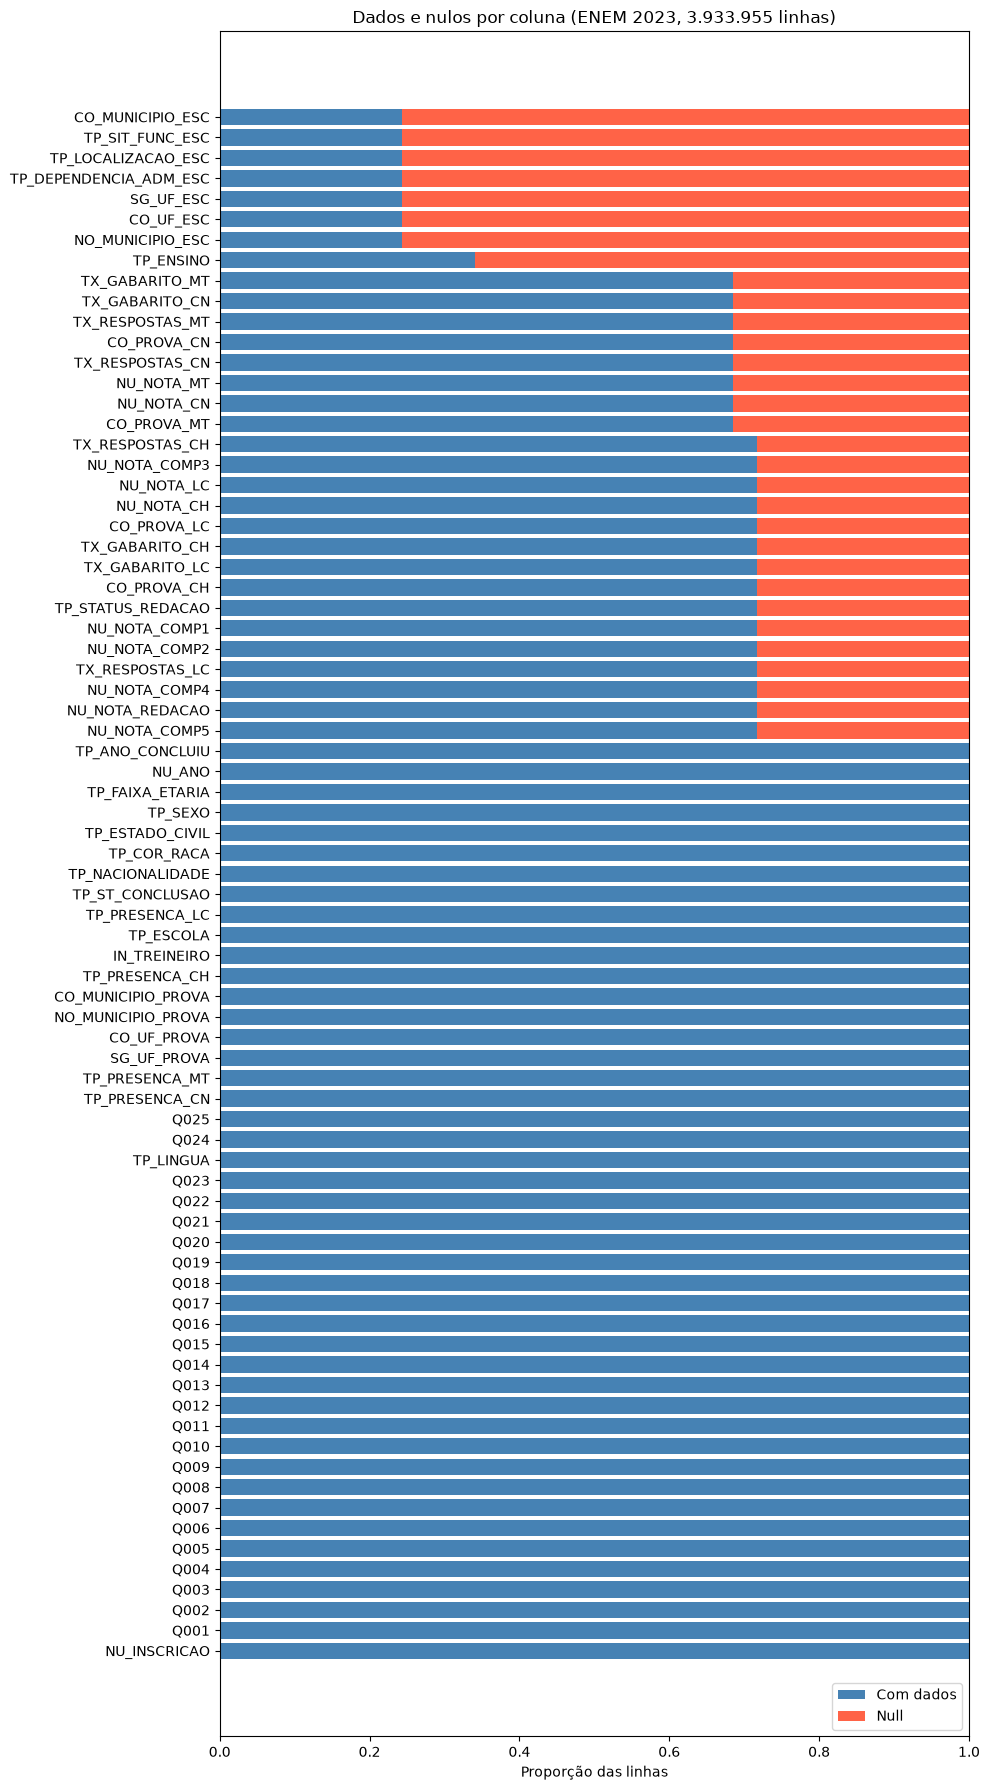

In [312]:
import matplotlib.pyplot as plt

nulos = df.isna().mean().sort_values()          # proporção de null por coluna
preenchidos = 1 - nulos

fig, ax = plt.subplots(figsize=(10, 18))
ax.barh(nulos.index, preenchidos, color="steelblue", label="Com dados")
ax.barh(nulos.index, nulos, left=preenchidos, color="tomato", label="Null")
ax.set_xlabel("Proporção das linhas")
ax.set_title("Dados e nulos por coluna (ENEM 2023, 3.933.955 linhas)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 3. Dicionário e classificação das colunas

Cada coluna recebe um uso: **alvo**, **identificador**, **fora de X** (nota, prova, gabarito e redação seriam vazamento)
ou **candidata a feature**. O dicionário `descricao` vem do dicionário oficial do Inep.

In [313]:
descricao = {
    # participante
    "NU_INSCRICAO": "Número de inscrição (máscara, só identificador)",
    "NU_ANO": "Ano do Enem (sempre 2023)",
    "TP_FAIXA_ETARIA": "Faixa etária em 31/12/2023 (1=menor de 17 ... 20=maior de 70)",
    "TP_SEXO": "Sexo (M/F)",
    "TP_ESTADO_CIVIL": "Estado civil (0=não informado, 1=solteiro, 2=casado, 3=divorciado, 4=viúvo)",
    "TP_COR_RACA": "Cor/raça (0=não declarado, 1=branca, 2=preta, 3=parda, 4=amarela, 5=indígena, 6=não dispõe)",
    "TP_NACIONALIDADE": "Nacionalidade (0=não informado, 1=brasileiro, 2=naturalizado, 3=estrangeiro, 4=nato no exterior)",
    "TP_ST_CONCLUSAO": "Situação do ensino médio (1=concluiu, 2=conclui em 2023, 3=conclui depois, 4=não concluiu nem cursa)",
    "TP_ANO_CONCLUIU": "Ano de conclusão (0=não informado, 1=2022 ... 16=2007, 17=antes de 2007)",
    "TP_ESCOLA": "Tipo de escola (1=não respondeu, 2=pública, 3=privada)",
    "TP_ENSINO": "Tipo de instituição (1=regular, 2=educação especial)",
    "IN_TREINEIRO": "Fez a prova só para treinar (1=sim, 0=não)",
    # escola
    "CO_MUNICIPIO_ESC": "Código do município da escola",
    "NO_MUNICIPIO_ESC": "Nome do município da escola",
    "CO_UF_ESC": "Código da UF da escola",
    "SG_UF_ESC": "Sigla da UF da escola",
    "TP_DEPENDENCIA_ADM_ESC": "Dependência da escola (1=federal, 2=estadual, 3=municipal, 4=privada)",
    "TP_LOCALIZACAO_ESC": "Localização da escola (1=urbana, 2=rural)",
    "TP_SIT_FUNC_ESC": "Situação da escola (1=em atividade, 2=paralisada, 3=extinta, 4=extinta antes)",
    # local da prova
    "CO_MUNICIPIO_PROVA": "Código do município da prova",
    "NO_MUNICIPIO_PROVA": "Nome do município da prova",
    "CO_UF_PROVA": "Código da UF da prova",
    "SG_UF_PROVA": "Sigla da UF da prova",
    # prova objetiva
    "TP_PRESENCA_CN": "Presença em Ciências da Natureza (0=faltou, 1=presente, 2=eliminado)",
    "TP_PRESENCA_CH": "Presença em Ciências Humanas",
    "TP_PRESENCA_LC": "Presença em Linguagens e Códigos",
    "TP_PRESENCA_MT": "Presença em Matemática",
    "CO_PROVA_CN": "Tipo de caderno de Ciências da Natureza",
    "CO_PROVA_CH": "Tipo de caderno de Ciências Humanas",
    "CO_PROVA_LC": "Tipo de caderno de Linguagens e Códigos",
    "CO_PROVA_MT": "Tipo de caderno de Matemática",
    "NU_NOTA_CN": "Nota de Ciências da Natureza",
    "NU_NOTA_CH": "Nota de Ciências Humanas",
    "NU_NOTA_LC": "Nota de Linguagens e Códigos",
    "NU_NOTA_MT": "Nota de Matemática (ALVO)",
    "TX_RESPOSTAS_CN": "Respostas marcadas em Ciências da Natureza",
    "TX_RESPOSTAS_CH": "Respostas marcadas em Ciências Humanas",
    "TX_RESPOSTAS_LC": "Respostas marcadas em Linguagens e Códigos",
    "TX_RESPOSTAS_MT": "Respostas marcadas em Matemática",
    "TP_LINGUA": "Língua estrangeira (0=inglês, 1=espanhol)",
    "TX_GABARITO_CN": "Gabarito de Ciências da Natureza",
    "TX_GABARITO_CH": "Gabarito de Ciências Humanas",
    "TX_GABARITO_LC": "Gabarito de Linguagens e Códigos",
    "TX_GABARITO_MT": "Gabarito de Matemática",
    # redação
    "TP_STATUS_REDACAO": "Situação da redação (1=sem problemas, 2=anulada, 4=em branco ...)",
    "NU_NOTA_COMP1": "Redação: competência 1 (norma culta)",
    "NU_NOTA_COMP2": "Redação: competência 2 (compreensão do tema)",
    "NU_NOTA_COMP3": "Redação: competência 3 (argumentação)",
    "NU_NOTA_COMP4": "Redação: competência 4 (coesão)",
    "NU_NOTA_COMP5": "Redação: competência 5 (proposta de intervenção)",
    "NU_NOTA_REDACAO": "Nota total da redação",
    # questionário
    "Q001": "Escolaridade do pai/responsável (A=nunca estudou ... G=pós, H=não sei)",
    "Q002": "Escolaridade da mãe/responsável (A=nunca estudou ... G=pós, H=não sei)",
    "Q003": "Grupo de ocupação do pai (A a E, F=não sei)",
    "Q004": "Grupo de ocupação da mãe (A a E, F=não sei)",
    "Q005": "Pessoas que moram na casa (1 a 20)",
    "Q006": "Renda mensal da família (A=nenhuma ... Q=acima de R$ 26.400)",
    "Q007": "Empregado doméstico (A=não, B-D=dias por semana)",
    "Q008": "Banheiros (A=não, B=1 ... E=4 ou mais)",
    "Q009": "Quartos",
    "Q010": "Carros",
    "Q011": "Motocicletas",
    "Q012": "Geladeiras",
    "Q013": "Freezers",
    "Q014": "Máquinas de lavar roupa",
    "Q015": "Máquinas de secar roupa",
    "Q016": "Micro-ondas",
    "Q017": "Máquinas de lavar louça",
    "Q018": "Aspirador de pó (A=não, B=sim)",
    "Q019": "TVs em cores",
    "Q020": "DVD (A=não, B=sim)",
    "Q021": "TV por assinatura (A=não, B=sim)",
    "Q022": "Celulares",
    "Q023": "Telefone fixo (A=não, B=sim)",
    "Q024": "Computadores",
    "Q025": "Acesso à internet (A=não, B=sim)",
}

len(descricao)   # deve dar 76

76

In [ ]:
ALVO = "NU_NOTA_MT"

def classificar(col):
    if col == ALVO:
        return "alvo (y)"
    if col == "NU_INSCRICAO":
        return "identificador"
    if (col.startswith(("NU_NOTA", "TX_", "TP_PRESENCA", "CO_PROVA"))
            or col in ("TP_STATUS_REDACAO", "NU_ANO")):
        return "fora de X"
    return "candidata a feature"

tabela = pd.DataFrame({
    "coluna": df.columns,
    "uso": [classificar(c) for c in df.columns],
    "descricao": [descricao[c] for c in df.columns],
    "% null": (df.isna().mean() * 100).round(1).values,
})

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 100)
tabela

In [ ]:
tabela["uso"].value_counts()

uso
candidata a feature    47
fora de X              27
identificador           1
alvo (y)                1
Name: count, dtype: int64

In [ ]:
candidatas = tabela.loc[tabela["uso"] == "candidata a feature", "coluna"].tolist()
print(len(candidatas), "candidatas")
candidatas

47 candidatas


['TP_FAIXA_ETARIA',
 'TP_SEXO',
 'TP_ESTADO_CIVIL',
 'TP_COR_RACA',
 'TP_NACIONALIDADE',
 'TP_ST_CONCLUSAO',
 'TP_ANO_CONCLUIU',
 'TP_ESCOLA',
 'TP_ENSINO',
 'IN_TREINEIRO',
 'CO_MUNICIPIO_ESC',
 'NO_MUNICIPIO_ESC',
 'CO_UF_ESC',
 'SG_UF_ESC',
 'TP_DEPENDENCIA_ADM_ESC',
 'TP_LOCALIZACAO_ESC',
 'TP_SIT_FUNC_ESC',
 'CO_MUNICIPIO_PROVA',
 'NO_MUNICIPIO_PROVA',
 'CO_UF_PROVA',
 'SG_UF_PROVA',
 'TP_LINGUA',
 'Q001',
 'Q002',
 'Q003',
 'Q004',
 'Q005',
 'Q006',
 'Q007',
 'Q008',
 'Q009',
 'Q010',
 'Q011',
 'Q012',
 'Q013',
 'Q014',
 'Q015',
 'Q016',
 'Q017',
 'Q018',
 'Q019',
 'Q020',
 'Q021',
 'Q022',
 'Q023',
 'Q024',
 'Q025']

## 4. Remoção de candidatas com mais de 50% de null

Corte de 50%: saem 7 colunas da escola e `TP_ENSINO` (8 no total). Ficam 39 features.
O null dessas colunas tem significado ("sem escola informada", "não se aplica"), então a perda de informação pode virar hipótese depois.

In [ ]:
resumo = pd.DataFrame({
    "% null": (df[candidatas].isna().mean() * 100).round(1),
    "qtd null": df[candidatas].isna().sum(),
}).sort_values("% null", ascending=False)

resumo.head(15)

,% null,qtd null
SG_UF_ESC,75.6,2975449
CO_MUNICIPIO_ESC,75.6,2975449
TP_LOCALIZACAO_ESC,75.6,2975449
TP_DEPENDENCIA_ADM_ESC,75.6,2975449
CO_UF_ESC,75.6,2975449
NO_MUNICIPIO_ESC,75.6,2975449
TP_SIT_FUNC_ESC,75.6,2975449
TP_ENSINO,66.0,2594874
Q014,0.0,0
Q017,0.0,0


In [ ]:
LIMITE = 50  # em %

pct_nulo = df[candidatas].isna().mean() * 100

removidas = pct_nulo[pct_nulo > LIMITE].sort_values(ascending=False)
features = [c for c in candidatas if c not in removidas.index]

print("Removidas:")
print(removidas.round(1))
print(f"\nFicaram {len(features)} features de {len(candidatas)} candidatas")
features

Removidas:
CO_MUNICIPIO_ESC          75.6
NO_MUNICIPIO_ESC          75.6
CO_UF_ESC                 75.6
SG_UF_ESC                 75.6
TP_DEPENDENCIA_ADM_ESC    75.6
TP_LOCALIZACAO_ESC        75.6
TP_SIT_FUNC_ESC           75.6
TP_ENSINO                 66.0
dtype: float64

Ficaram 39 features de 47 candidatas


['TP_FAIXA_ETARIA',
 'TP_SEXO',
 'TP_ESTADO_CIVIL',
 'TP_COR_RACA',
 'TP_NACIONALIDADE',
 'TP_ST_CONCLUSAO',
 'TP_ANO_CONCLUIU',
 'TP_ESCOLA',
 'IN_TREINEIRO',
 'CO_MUNICIPIO_PROVA',
 'NO_MUNICIPIO_PROVA',
 'CO_UF_PROVA',
 'SG_UF_PROVA',
 'TP_LINGUA',
 'Q001',
 'Q002',
 'Q003',
 'Q004',
 'Q005',
 'Q006',
 'Q007',
 'Q008',
 'Q009',
 'Q010',
 'Q011',
 'Q012',
 'Q013',
 'Q014',
 'Q015',
 'Q016',
 'Q017',
 'Q018',
 'Q019',
 'Q020',
 'Q021',
 'Q022',
 'Q023',
 'Q024',
 'Q025']

## 5. Linhas sem nota de Matemática e identificador

Quem não tem nota faltou ou foi eliminado: sai do estudo (nota ausente não vira zero e não é imputada).
`NU_INSCRICAO` fica guardado à parte em `ids` e sai do `df`. Esperado: `(2692427, 75)`.

In [ ]:
# 1. Remove as linhas sem nota de Matemática (null/NaN)
df = df[df["NU_NOTA_MT"].notna()].reset_index(drop=True)

# 2. Guarda os números de inscrição à parte e remove a coluna do df
ids = df["NU_INSCRICAO"].copy()
df = df.drop(columns="NU_INSCRICAO")

print(df.shape)
print("Nulls restantes em NU_NOTA_MT:", df["NU_NOTA_MT"].isna().sum())

(2692427, 75)
Nulls restantes em NU_NOTA_MT: 0


## 6. `df_modelo`: features e alvo

Só as 39 features mais o alvo. Depois confere se alguma linha tem null nas features (esperado: nenhuma).

In [ ]:
colunas_finais = features + [ALVO]

df_modelo = df[colunas_finais].copy()
print(df_modelo.shape)
df_modelo.head()

(2692427, 40)


,TP_FAIXA_ETARIA,TP_SEXO,TP_ESTADO_CIVIL,TP_COR_RACA,TP_NACIONALIDADE,TP_ST_CONCLUSAO,TP_ANO_CONCLUIU,TP_ESCOLA,IN_TREINEIRO,CO_MUNICIPIO_PROVA,NO_MUNICIPIO_PROVA,CO_UF_PROVA,SG_UF_PROVA,TP_LINGUA,Q001,Q002,Q003,Q004,Q005,Q006,Q007,Q008,Q009,Q010,Q011,Q012,Q013,Q014,Q015,Q016,Q017,Q018,Q019,Q020,Q021,Q022,Q023,Q024,Q025,NU_NOTA_MT
0,6,F,1,1,1,1,0,1,0,4305108,Caxias do Sul,43,RS,1,H,E,C,F,5,C,A,B,D,B,A,B,A,B,A,B,A,A,B,A,A,A,A,A,B,363.2
1,2,F,1,3,1,2,0,2,0,2304400,Fortaleza,23,CE,0,D,D,B,B,5,C,A,B,B,A,A,B,A,A,A,A,A,A,B,A,A,D,A,A,B,466.7
2,3,F,1,3,1,2,0,2,0,2311306,Quixadá,23,CE,0,B,B,A,A,4,B,A,B,A,A,A,B,A,A,A,A,A,A,B,A,A,B,A,A,A,338.3
3,11,M,1,1,1,1,8,1,0,3505906,Batatais,35,SP,0,H,E,F,D,2,F,A,B,C,B,B,B,B,B,A,B,A,B,C,B,A,C,A,B,B,680.2
4,8,M,1,3,1,1,5,1,0,2408102,Natal,24,RN,0,F,C,D,B,4,B,A,C,C,A,A,B,A,B,A,B,A,B,B,A,A,E,A,B,B,736.3


In [ ]:
linhas_com_null = df_modelo.isna().any(axis=1)

print(f"Linhas com pelo menos 1 null: {linhas_com_null.sum():,} ({linhas_com_null.mean():.2%})")
print(f"Linhas que ficariam:          {(~linhas_com_null).sum():,}")

# quais colunas têm null e quantos
nulos_col = df_modelo.isna().sum()
nulos_col[nulos_col > 0].sort_values(ascending=False)

Linhas com pelo menos 1 null: 0 (0.00%)
Linhas que ficariam:          2,692,427


Series([], dtype: int64)

In [ ]:
df_modelo = df_modelo[~linhas_com_null].reset_index(drop=True)
ids = ids[~linhas_com_null.values].reset_index(drop=True)  # mantém os IDs alinhados

print(df_modelo.shape)
print("Nulls restantes:", df_modelo.isna().sum().sum())

(2692427, 40)
Nulls restantes: 0


In [ ]:
print(len(df_modelo.columns), "colunas")
df_modelo.columns.tolist()

40 colunas


['TP_FAIXA_ETARIA',
 'TP_SEXO',
 'TP_ESTADO_CIVIL',
 'TP_COR_RACA',
 'TP_NACIONALIDADE',
 'TP_ST_CONCLUSAO',
 'TP_ANO_CONCLUIU',
 'TP_ESCOLA',
 'IN_TREINEIRO',
 'CO_MUNICIPIO_PROVA',
 'NO_MUNICIPIO_PROVA',
 'CO_UF_PROVA',
 'SG_UF_PROVA',
 'TP_LINGUA',
 'Q001',
 'Q002',
 'Q003',
 'Q004',
 'Q005',
 'Q006',
 'Q007',
 'Q008',
 'Q009',
 'Q010',
 'Q011',
 'Q012',
 'Q013',
 'Q014',
 'Q015',
 'Q016',
 'Q017',
 'Q018',
 'Q019',
 'Q020',
 'Q021',
 'Q022',
 'Q023',
 'Q024',
 'Q025',
 'NU_NOTA_MT']

## 7. Versão numérica (`df_num`)

Prepara as colunas para o Spearman:
- sexo em 0/1;
- letras do questionário em números (A=0, B=1, C=2...). O teste usa `is_string_dtype`, porque no pandas 3 o texto tem dtype `str` e não `object`;
- "não sei" (H em Q001 e Q002, F em Q003 e Q004) e "não informado" (código 0 de `TP_ANO_CONCLUIU`) viram `NaN`;
- as colunas de local da prova ficam fora desta versão (decisão pendente, ver o fim do notebook).

In [ ]:
df_num = df_modelo.drop(
    columns=["SG_UF_PROVA", "CO_MUNICIPIO_PROVA", "CO_UF_PROVA", "NO_MUNICIPIO_PROVA"],
    errors="ignore",
).copy()

# sexo em 0/1
df_num["TP_SEXO"] = df_num["TP_SEXO"].map({"M": 0, "F": 1})

# letras do questionário viram números: A=0, B=1, C=2...
mapa = {chr(65 + i): i for i in range(17)}
for col in df_num.columns:
    if col.startswith("Q") and pd.api.types.is_string_dtype(df_num[col]):
        df_num[col] = df_num[col].map(mapa)

# "não sei" e "não informado" não são posições na escala: viram NaN
for col, cod in {"Q001": 7, "Q002": 7, "Q003": 5, "Q004": 5}.items():
    df_num[col] = df_num[col].mask(df_num[col] == cod)
df_num["TP_ANO_CONCLUIU"] = df_num["TP_ANO_CONCLUIU"].mask(df_num["TP_ANO_CONCLUIU"] == 0)

texto = [col for col in df_num.columns if not pd.api.types.is_numeric_dtype(df_num[col])]
print("Colunas em texto:", texto if texto else "nenhuma")
print("Formato:", df_num.shape)
df_num.dtypes.value_counts()

Colunas em texto: nenhuma
Formato: (2692427, 36)


int64      30
float64     6
Name: count, dtype: int64

## 7b. Exploração por sexo e língua (antes do tratamento)

Descrição dos dados feita **antes** da fusão e do preenchimento de "não sei". Usa `df_num` (`TP_SEXO`: 0 = homens, 1 = mulheres; `TP_LINGUA`: 0 = inglês, 1 = espanhol).
Só descreve: nenhuma decisão do modelo sai daqui. Os números usam as 2.692.427 linhas, ainda sem a divisão 80/20.

### Quem faz mais o Enem: homens ou mulheres?

Total: 2,692,427 participantes com nota de Matemática
  Homens     1,040,942  (38.7%)
  Mulheres   1,651,485  (61.3%)

Para cada 100 homens há 159 mulheres.


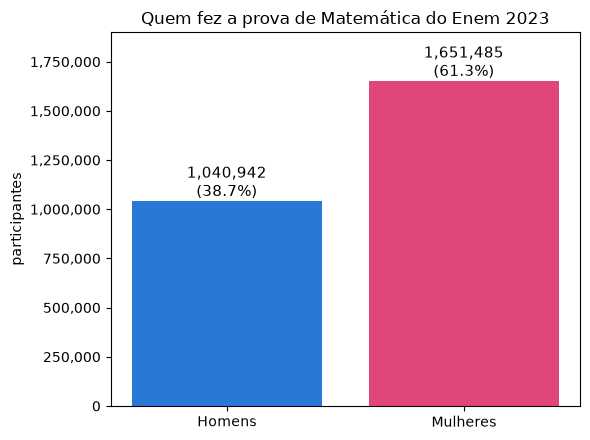

In [ ]:
# Quem faz mais o Enem: homens ou mulheres? (entre quem fez a prova de Matemática)
rotulo = {0: "Homens", 1: "Mulheres"}
cores = {"Homens": "#2a78d6", "Mulheres": "#e0457b"}

contagem = df_num["TP_SEXO"].map(rotulo).value_counts().reindex(["Homens", "Mulheres"])
pct = contagem / contagem.sum() * 100

print(f"Total: {contagem.sum():,} participantes com nota de Matemática")
for g in contagem.index:
    print(f"  {g:<9} {contagem[g]:>10,}  ({pct[g]:.1f}%)")
print(f"\nPara cada 100 homens há {contagem['Mulheres'] / contagem['Homens'] * 100:.0f} mulheres.")

fig, ax = plt.subplots(figsize=(6, 4.5))
barras = ax.bar(contagem.index, contagem.values, color=[cores[g] for g in contagem.index])
for b, n, p in zip(barras, contagem.values, pct.values):
    ax.text(b.get_x() + b.get_width() / 2, n, f"{n:,.0f}\n({p:.1f}%)", ha="center", va="bottom", fontsize=11)
ax.set_ylim(0, contagem.max() * 1.15)
ax.set_ylabel("participantes")
ax.set_title("Quem fez a prova de Matemática do Enem 2023")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
plt.tight_layout()
plt.show()

### E entre todos os inscritos, inclusive quem faltou?

Confere se a proporção muda quando entram os 1,24 milhão de inscritos sem nota. Lê só `TP_SEXO` e `NU_NOTA_MT` do CSV bruto (rápido).

          inscritos  % dos inscritos  fizeram a prova de Matemática  % de quem fez a prova  % do grupo que fez a prova
sexo                                                                                                                  
Homens      1522770             38.7                        1040942                   38.7                        68.4
Mulheres    2411185             61.3                        1651485                   61.3                        68.5

Total de inscritos: 3,933,955  |  fizeram a prova: 2,692,427


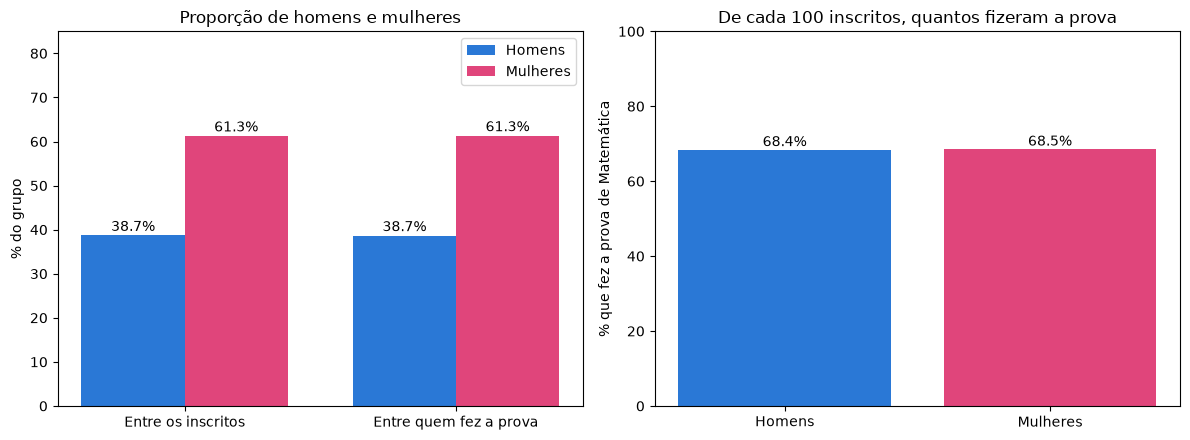

In [ ]:
# Todos os inscritos, inclusive quem faltou ou foi eliminado (sem nota). Lê só 2 colunas do CSV bruto.
bruto = pd.read_csv("../dados/raw/DADOS/MICRODADOS_ENEM_2023.csv", sep=";", encoding="latin-1",
                    usecols=["TP_SEXO", "NU_NOTA_MT"])
bruto["sexo"] = bruto["TP_SEXO"].map({"M": "Homens", "F": "Mulheres"})
bruto["fez"] = bruto["NU_NOTA_MT"].notna()

ordem = ["Homens", "Mulheres"]
cores = {"Homens": "#2a78d6", "Mulheres": "#e0457b"}

inscritos = bruto["sexo"].value_counts().reindex(ordem)
fizeram = bruto.loc[bruto["fez"], "sexo"].value_counts().reindex(ordem)
comparecimento = fizeram / inscritos * 100

tabela = pd.DataFrame({
    "inscritos": inscritos,
    "% dos inscritos": inscritos / inscritos.sum() * 100,
    "fizeram a prova de Matemática": fizeram,
    "% de quem fez a prova": fizeram / fizeram.sum() * 100,
    "% do grupo que fez a prova": comparecimento,
})
print(tabela.round(1).to_string())
print(f"\nTotal de inscritos: {inscritos.sum():,}  |  fizeram a prova: {fizeram.sum():,}")

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))

# 1. proporção de cada sexo: entre inscritos e entre quem fez a prova
x = np.arange(2)
for i, g in enumerate(ordem):
    valores = [inscritos[g] / inscritos.sum() * 100, fizeram[g] / fizeram.sum() * 100]
    barras = eixos[0].bar(x + (i - 0.5) * 0.38, valores, 0.38, color=cores[g], label=g)
    for b, v in zip(barras, valores):
        eixos[0].text(b.get_x() + b.get_width() / 2, v + 1, f"{v:.1f}%", ha="center")
eixos[0].set_xticks(x)
eixos[0].set_xticklabels(["Entre os inscritos", "Entre quem fez a prova"])
eixos[0].set_ylim(0, 85)
eixos[0].set_ylabel("% do grupo")
eixos[0].set_title("Proporção de homens e mulheres")
eixos[0].legend()

# 2. de cada 100 inscritos do sexo, quantos fizeram a prova
barras = eixos[1].bar(ordem, comparecimento.values, color=[cores[g] for g in ordem])
for b, v in zip(barras, comparecimento.values):
    eixos[1].text(b.get_x() + b.get_width() / 2, v + 1, f"{v:.1f}%", ha="center")
eixos[1].set_ylim(0, 100)
eixos[1].set_ylabel("% que fez a prova de Matemática")
eixos[1].set_title("De cada 100 inscritos, quantos fizeram a prova")

plt.tight_layout()
plt.show()
del bruto   # libera memória

### Quem tira notas maiores: homens ou mulheres?

          participantes  media  mediana  desvio    q25    q75  % acima de 700  % acima de 800
sexo                                                                                         
Homens          1040942  560.8    561.1   136.9  454.5  662.6            16.3             3.4
Mulheres        1651485  516.8    503.0   125.3  420.5  604.8             8.5             1.3

Diferença de média (homens - mulheres): +44.0 pontos
Tamanho do efeito (diferença / desvio): +0.33  (0,2 = pequeno, 0,5 = médio, 0,8 = grande)


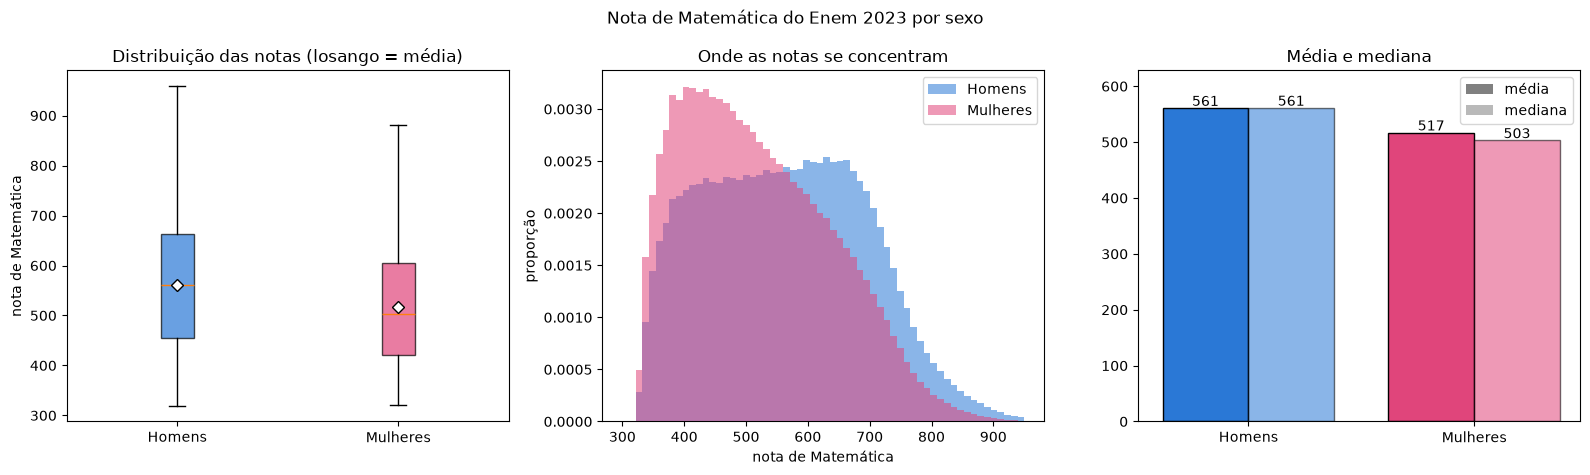

In [ ]:
# Quem tira notas maiores no Enem: homens ou mulheres?
rotulo = {0: "Homens", 1: "Mulheres"}
cores = {"Homens": "#2a78d6", "Mulheres": "#e0457b"}
ordem = ["Homens", "Mulheres"]

d = pd.DataFrame({"sexo": df_num["TP_SEXO"].map(rotulo), "nota": df_num[ALVO]})
notas = {g: d.loc[d["sexo"] == g, "nota"] for g in ordem}

resumo = d.groupby("sexo")["nota"].agg(
    participantes="count", media="mean", mediana="median", desvio="std",
    q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75),
).loc[ordem]
resumo["% acima de 700"] = [(notas[g] > 700).mean() * 100 for g in ordem]
resumo["% acima de 800"] = [(notas[g] > 800).mean() * 100 for g in ordem]
print(resumo.round(1).to_string())

dif = notas["Homens"].mean() - notas["Mulheres"].mean()
desvio_comum = np.sqrt((notas["Homens"].var() + notas["Mulheres"].var()) / 2)
print(f"\nDiferença de média (homens - mulheres): {dif:+.1f} pontos")
print(f"Tamanho do efeito (diferença / desvio): {dif / desvio_comum:+.2f}  (0,2 = pequeno, 0,5 = médio, 0,8 = grande)")

fig, eixos = plt.subplots(1, 3, figsize=(16, 4.8))

# 1. boxplot
bp = eixos[0].boxplot([notas[g] for g in ordem], tick_labels=ordem, showfliers=False, patch_artist=True,
                      showmeans=True, meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black"))
for caixa, g in zip(bp["boxes"], ordem):
    caixa.set_facecolor(cores[g])
    caixa.set_alpha(0.7)
eixos[0].set_title("Distribuição das notas (losango = média)")
eixos[0].set_ylabel("nota de Matemática")

# 2. histograma sobreposto (proporção, porque há mais mulheres que homens)
for g in ordem:
    eixos[1].hist(notas[g], bins=60, range=(300, 950), density=True, alpha=0.55, color=cores[g], label=g)
eixos[1].set_title("Onde as notas se concentram")
eixos[1].set_xlabel("nota de Matemática")
eixos[1].set_ylabel("proporção")
eixos[1].legend()

# 3. média e mediana
x = np.arange(len(ordem))
larg = 0.38
for i, (nome, serie) in enumerate([("média", resumo["media"]), ("mediana", resumo["mediana"])]):
    barras = eixos[2].bar(x + (i - 0.5) * larg, serie.values, larg,
                          color=[cores[g] for g in ordem], alpha=1 if i == 0 else 0.55, edgecolor="black")
    for b, v in zip(barras, serie.values):
        eixos[2].text(b.get_x() + b.get_width() / 2, v + 4, f"{v:.0f}", ha="center", fontsize=10)
    eixos[2].bar(0, 0, color="gray", alpha=1 if i == 0 else 0.55, label=nome)
eixos[2].set_xticks(x)
eixos[2].set_xticklabels(ordem)
eixos[2].set_ylim(0, resumo[["media", "mediana"]].values.max() * 1.12)
eixos[2].set_title("Média e mediana")
eixos[2].legend()

plt.suptitle("Nota de Matemática do Enem 2023 por sexo")
plt.tight_layout()
plt.show()

### Quem tira notas maiores: inglês ou espanhol?

`TP_LINGUA` é a língua estrangeira escolhida na prova (0 = inglês, 1 = espanhol). Mesma análise do sexo: tabela, diferença de médias, tamanho do efeito e três gráficos.

          participantes  media  mediana  desvio    q25    q75  % do total  % acima de 700  % acima de 800
lingua                                                                                                   
Inglês          1555044  565.3    566.7   134.2  462.7  665.1        57.8            16.7             3.3
Espanhol        1137383  490.8    475.2   114.8  405.5  566.0        42.2             4.4             0.5

Diferença de média (inglês - espanhol): +74.5 pontos
Tamanho do efeito (diferença / desvio): +0.60  (0,2 = pequeno, 0,5 = médio, 0,8 = grande)


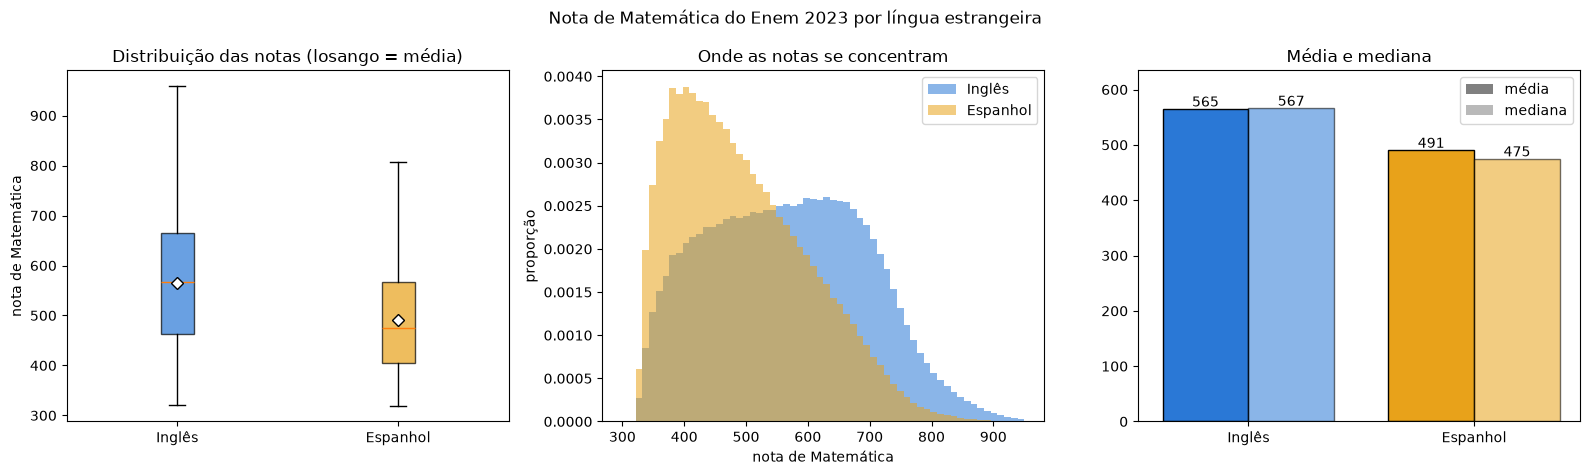

In [ ]:
# Nota de Matemática por língua estrangeira escolhida (TP_LINGUA: 0 = inglês, 1 = espanhol)
rotulo = {0: "Inglês", 1: "Espanhol"}
cores = {"Inglês": "#2a78d6", "Espanhol": "#e8a21a"}
ordem = ["Inglês", "Espanhol"]

d = pd.DataFrame({"lingua": df_num["TP_LINGUA"].map(rotulo), "nota": df_num[ALVO]})
notas = {g: d.loc[d["lingua"] == g, "nota"] for g in ordem}

resumo = d.groupby("lingua")["nota"].agg(
    participantes="count", media="mean", mediana="median", desvio="std",
    q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75),
).loc[ordem]
resumo["% do total"] = resumo["participantes"] / resumo["participantes"].sum() * 100
resumo["% acima de 700"] = [(notas[g] > 700).mean() * 100 for g in ordem]
resumo["% acima de 800"] = [(notas[g] > 800).mean() * 100 for g in ordem]
print(resumo.round(1).to_string())

dif = notas["Inglês"].mean() - notas["Espanhol"].mean()
desvio_comum = np.sqrt((notas["Inglês"].var() + notas["Espanhol"].var()) / 2)
print(f"\nDiferença de média (inglês - espanhol): {dif:+.1f} pontos")
print(f"Tamanho do efeito (diferença / desvio): {dif / desvio_comum:+.2f}  (0,2 = pequeno, 0,5 = médio, 0,8 = grande)")

fig, eixos = plt.subplots(1, 3, figsize=(16, 4.8))

# 1. boxplot
bp = eixos[0].boxplot([notas[g] for g in ordem], tick_labels=ordem, showfliers=False, patch_artist=True,
                      showmeans=True, meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black"))
for caixa, g in zip(bp["boxes"], ordem):
    caixa.set_facecolor(cores[g])
    caixa.set_alpha(0.7)
eixos[0].set_title("Distribuição das notas (losango = média)")
eixos[0].set_ylabel("nota de Matemática")

# 2. histograma sobreposto (proporção, porque há muito mais gente no inglês)
for g in ordem:
    eixos[1].hist(notas[g], bins=60, range=(300, 950), density=True, alpha=0.55, color=cores[g], label=g)
eixos[1].set_title("Onde as notas se concentram")
eixos[1].set_xlabel("nota de Matemática")
eixos[1].set_ylabel("proporção")
eixos[1].legend()

# 3. média e mediana
x = np.arange(len(ordem))
larg = 0.38
for i, (nome, serie) in enumerate([("média", resumo["media"]), ("mediana", resumo["mediana"])]):
    barras = eixos[2].bar(x + (i - 0.5) * larg, serie.values, larg,
                          color=[cores[g] for g in ordem], alpha=1 if i == 0 else 0.55, edgecolor="black")
    for b, v in zip(barras, serie.values):
        eixos[2].text(b.get_x() + b.get_width() / 2, v + 4, f"{v:.0f}", ha="center", fontsize=10)
    eixos[2].bar(0, 0, color="gray", alpha=1 if i == 0 else 0.55, label=nome)
eixos[2].set_xticks(x)
eixos[2].set_xticklabels(ordem)
eixos[2].set_ylim(0, resumo[["media", "mediana"]].values.max() * 1.12)
eixos[2].set_title("Média e mediana")
eixos[2].legend()

plt.suptitle("Nota de Matemática do Enem 2023 por língua estrangeira")
plt.tight_layout()
plt.show()

## 8. Spearman das colunas com a nota (antes da fusão)

O Spearman troca os valores por posições e vai de -1 a +1. Mostra relação, não causa. Leva cerca de 1 minuto.
Nas colunas sem ordem (cor, estado civil, nacionalidade, tipo de escola) o número do código é só rótulo, então o valor delas não deve ser interpretado.

In [ ]:
corr = df_num.rank().corr()          # Spearman = Pearson sobre os rankings
corr_alvo = corr[ALVO].drop(ALVO).sort_values(key=abs, ascending=False)
corr_alvo.round(3)

Q006                0.457
Q024                0.409
Q003                0.377
Q001                0.364
Q004                0.361
Q002                0.354
Q010                0.339
Q008                0.339
Q018                0.303
Q019                0.292
TP_LINGUA          -0.287
Q016                0.283
Q013                0.276
Q014                0.266
Q022                0.259
Q009                0.227
TP_COR_RACA        -0.222
Q021                0.188
Q025                0.179
Q007                0.177
TP_SEXO            -0.165
Q023                0.144
Q017                0.141
Q012                0.139
Q015                0.131
Q020                0.128
TP_FAIXA_ETARIA    -0.109
TP_ANO_CONCLUIU    -0.063
TP_NACIONALIDADE   -0.047
Q005               -0.045
IN_TREINEIRO        0.040
Q011               -0.033
TP_ESTADO_CIVIL    -0.031
TP_ESCOLA           0.029
TP_ST_CONCLUSAO     0.026
Name: NU_NOTA_MT, dtype: float64

In [ ]:
dados = corr_alvo.sort_values().reset_index()
dados.columns = ["feature", "spearman"]

fig = px.bar(
    dados, x="spearman", y="feature", orientation="h",
    color="spearman", color_continuous_scale="RdBu_r", range_color=[-1, 1],
    title="Spearman de cada feature com NU_NOTA_MT",
)
fig.update_layout(width=800, height=800)
fig.show()

In [ ]:
import plotly.express as px

fig = px.imshow(
    corr.round(2),
    color_continuous_scale="RdBu_r",
    zmin=-1, zmax=1,
    aspect="auto",
    title="Spearman entre as colunas",
)
fig.update_layout(width=950, height=850)
fig.show()

In [ ]:
import ipywidgets as widgets
from IPython.display import display

def mostrar(limite):
    filtrado = corr.where(corr.abs() >= limite)
    fig = px.imshow(filtrado.round(2), color_continuous_scale="RdBu_r",
                    zmin=-1, zmax=1, aspect="auto",
                    title=f"Pares com |Spearman| >= {limite}")
    fig.update_layout(width=950, height=850)
    fig.show()

widgets.interact(mostrar, limite=widgets.FloatSlider(value=0.5, min=0, max=1, step=0.05))

interactive(children=(FloatSlider(value=0.5, description='limite', max=1.0, step=0.05), Output()), _dom_classe…

<function __main__.mostrar(limite)>

## 9. Colunas redundantes e fusão

1. Lista os pares com |Spearman| > 0,7 (`pares`). Colunas sem ordem (`NOMINAIS`) não são fundidas.
2. Mostra os pares num scatter (amostra de 20 mil pontos, só para desenhar).
3. Junta os pares em grupos e funde cada grupo numa coluna nova: a média das colunas padronizadas (z-score).
   Colunas com correlação **negativa** com a referência do grupo têm o sinal invertido antes da média, para não se cancelarem.
4. Imprime o relatório: o que fundiu, o que saiu, o que ficou e por quê.

A média e o desvio da padronização usam todas as linhas. No pipeline final isso deve ser refeito só no treino.

In [ ]:
LIMITE = 0.7

# colunas sem ordem: o Spearman delas não faz sentido, então não fundimos
NOMINAIS = ["TP_COR_RACA", "TP_ESTADO_CIVIL", "TP_NACIONALIDADE",
            "TP_ESCOLA", "TP_SEXO", "TP_LINGUA"]

cc = corr.drop(index=ALVO, columns=ALVO)                          # tira a nota
triangulo = cc.where(np.triu(np.ones(cc.shape, dtype=bool), k=1)) # cada par só uma vez
pares = triangulo.stack().dropna().rename("spearman").reset_index()
pares.columns = ["coluna_1", "coluna_2", "spearman"]

pares = pares[pares["spearman"].abs() > LIMITE].sort_values("spearman", key=abs, ascending=False)
pares["pode_fundir"] = ~(pares["coluna_1"].isin(NOMINAIS) | pares["coluna_2"].isin(NOMINAIS))

print(f"{len(pares)} pares com |Spearman| > {LIMITE}")
pares.round(3).reset_index(drop=True)

3 pares com |Spearman| > 0.7


,coluna_1,coluna_2,spearman,pode_fundir
0,TP_FAIXA_ETARIA,TP_ANO_CONCLUIU,0.885,True
1,TP_FAIXA_ETARIA,TP_ST_CONCLUSAO,-0.842,True
2,TP_ST_CONCLUSAO,IN_TREINEIRO,0.728,True


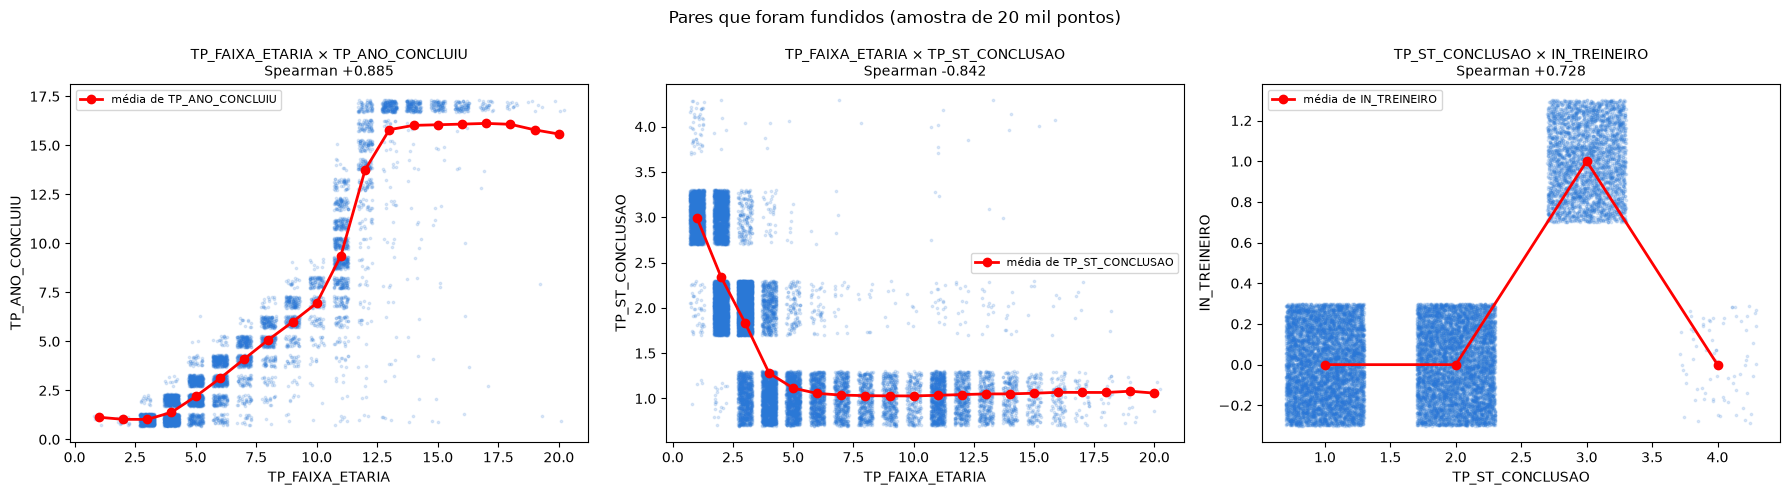

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

pares_plot = pares[pares["pode_fundir"]].head(3)

amostra = df_num.sample(20000, random_state=42)     # só para desenhar; o Spearman foi calculado com todas as linhas
rng = np.random.default_rng(42)

fig, eixos = plt.subplots(1, len(pares_plot), figsize=(6 * len(pares_plot), 5))
eixos = np.atleast_1d(eixos)

for ax, r in zip(eixos, pares_plot.itertuples()):
    a, b = r.coluna_1, r.coluna_2
    x = amostra[a] + rng.uniform(-0.3, 0.3, len(amostra))   # jitter para os pontos não se empilharem
    y = amostra[b] + rng.uniform(-0.3, 0.3, len(amostra))
    ax.scatter(x, y, s=3, alpha=0.15, color="#2a78d6")

    medias = df_num.groupby(a)[b].mean()                    # valor médio de b para cada nível de a
    ax.plot(medias.index, medias.values, "o-", color="red", linewidth=2, label=f"média de {b}")

    ax.set_title(f"{a} × {b}\nSpearman {r.spearman:+.3f}", fontsize=10)
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.legend(fontsize=8)

plt.suptitle("Pares que foram fundidos (amostra de 20 mil pontos)")
plt.tight_layout()
plt.show()

In [ ]:
fundiveis = pares[pares["pode_fundir"]]

# 1. Monta os grupos (colunas ligadas por pares acima do limite)
grupos = []
for a, b in zip(fundiveis["coluna_1"], fundiveis["coluna_2"]):
    juntos = [g for g in grupos if a in g or b in g]
    novo = {a, b}.union(*juntos)
    grupos = [g for g in grupos if g not in juntos] + [novo]

# 2. Funde e imprime o relatório
df_fundido = df_num.copy()
removidas = []
novas = []

print("=" * 70)
print(f"RELATÓRIO DA FUSÃO (limite |Spearman| > {LIMITE})")
print("=" * 70)

if not grupos:
    print("\nNenhum grupo para fundir.")

for i, g in enumerate(grupos, 1):
    cols = sorted(g)
    ref = cols[0]

    z = (df_fundido[cols] - df_fundido[cols].mean()) / df_fundido[cols].std()
    sinais = {c: (1 if c == ref or corr.loc[ref, c] >= 0 else -1) for c in cols}
    for c in cols:
        z[c] = z[c] * sinais[c]

    nome = f"FUSAO_{i}"
    df_fundido[nome] = z.mean(axis=1)
    df_fundido = df_fundido.drop(columns=cols)
    removidas += cols
    novas.append(nome)

    print(f"\n>>> {nome}")
    print(f"  FUNDIU {len(cols)} colunas: {cols}")
    print(f"  MOTIVO, pares com |Spearman| > {LIMITE}:")
    for r in fundiveis.itertuples():
        if r.coluna_1 in g:
            print(f"     {r.coluna_1}  x  {r.coluna_2}:  {r.spearman:+.3f}")
    invertidas = [c for c, s in sinais.items() if s == -1]
    if invertidas:
        print(f"  SINAL INVERTIDO antes da média: {invertidas}")
        print(f"     (têm correlação negativa com '{ref}', então 'subiam' quando '{ref}' descia)")
    else:
        print("  Nenhum sinal precisou ser invertido.")

# 3. Colunas tiradas
print("\n" + "=" * 70)
print("TIRADAS DO DATAFRAME (substituídas pelas colunas FUSAO_*)")
print("=" * 70)
print(removidas if removidas else "Nenhuma.")

# 4. Colunas que ficaram como estavam, e por quê
com_par_nominal = set(pares.loc[~pares["pode_fundir"], ["coluna_1", "coluna_2"]].values.ravel())
motivos = {}
for col in df_num.columns:
    if col in removidas or col == ALVO:
        continue
    if col in NOMINAIS:
        m = "sem ordem numérica (categoria), não se funde"
    elif col in com_par_nominal:
        m = "só tem par alto com coluna sem ordem, então não se funde"
    else:
        m = f"nenhum par com |Spearman| > {LIMITE}"
    motivos.setdefault(m, []).append(col)

print("\n" + "=" * 70)
print("FICARAM COMO ESTAVAM")
print("=" * 70)
for m, lista in motivos.items():
    print(f"\n{m} ({len(lista)}):")
    print(f"   {lista}")

# 5. Resumo
print("\n" + "=" * 70)
print(f"Antes: {df_num.shape[1]} colunas | Depois: {df_fundido.shape[1]} colunas")
if novas:
    print("\nSpearman das colunas novas com a nota:")
    print(df_fundido[novas + [ALVO]].rank().corr()[ALVO].drop(ALVO).round(3).to_string())

RELATÓRIO DA FUSÃO (limite |Spearman| > 0.7)

>>> FUSAO_1
  FUNDIU 4 colunas: ['IN_TREINEIRO', 'TP_ANO_CONCLUIU', 'TP_FAIXA_ETARIA', 'TP_ST_CONCLUSAO']
  MOTIVO, pares com |Spearman| > 0.7:
     TP_FAIXA_ETARIA  x  TP_ANO_CONCLUIU:  +0.885
     TP_FAIXA_ETARIA  x  TP_ST_CONCLUSAO:  -0.842
     TP_ST_CONCLUSAO  x  IN_TREINEIRO:  +0.728
  SINAL INVERTIDO antes da média: ['TP_ANO_CONCLUIU', 'TP_FAIXA_ETARIA']
     (têm correlação negativa com 'IN_TREINEIRO', então 'subiam' quando 'IN_TREINEIRO' descia)

TIRADAS DO DATAFRAME (substituídas pelas colunas FUSAO_*)
['IN_TREINEIRO', 'TP_ANO_CONCLUIU', 'TP_FAIXA_ETARIA', 'TP_ST_CONCLUSAO']

FICARAM COMO ESTAVAM

sem ordem numérica (categoria), não se funde (6):
   ['TP_SEXO', 'TP_ESTADO_CIVIL', 'TP_COR_RACA', 'TP_NACIONALIDADE', 'TP_ESCOLA', 'TP_LINGUA']

nenhum par com |Spearman| > 0.7 (25):
   ['Q001', 'Q002', 'Q003', 'Q004', 'Q005', 'Q006', 'Q007', 'Q008', 'Q009', 'Q010', 'Q011', 'Q012', 'Q013', 'Q014', 'Q015', 'Q016', 'Q017', 'Q018', 'Q019',

Spearman entre IN_TREINEIRO e TP_FAIXA_ETARIA: -0.605
Desvio padrão da média SEM inverter: 0.549
Desvio padrão da média INVERTENDO:   0.836


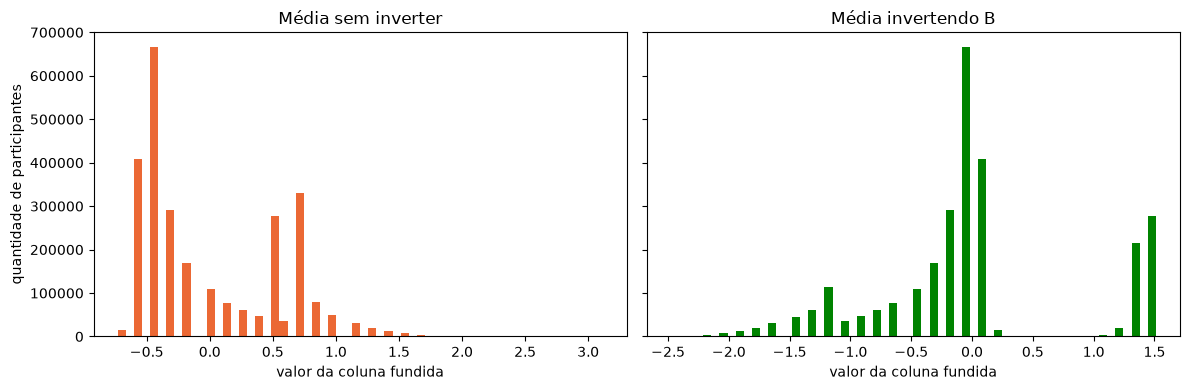

In [ ]:
a, b = "IN_TREINEIRO", "TP_FAIXA_ETARIA"

z = (df_num[[a, b]] - df_num[[a, b]].mean()) / df_num[[a, b]].std()

sem_inverter = (z[a] + z[b]) / 2
invertendo = (z[a] - z[b]) / 2

print(f"Spearman entre {a} e {b}: {corr.loc[a, b]:+.3f}")
print(f"Desvio padrão da média SEM inverter: {sem_inverter.std():.3f}")
print(f"Desvio padrão da média INVERTENDO:   {invertendo.std():.3f}")

fig, eixos = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
eixos[0].hist(sem_inverter, bins=60, color="#eb6834")
eixos[0].set_title("Média sem inverter")
eixos[1].hist(invertendo, bins=60, color="#008300")
eixos[1].set_title("Média invertendo B")
for e in eixos:
    e.set_xlabel("valor da coluna fundida")
eixos[0].set_ylabel("quantidade de participantes")
plt.tight_layout()
plt.show()

## 10. Spearman depois do tratamento

Mesma análise da seção 8, agora no `df_fundido`: quais colunas ficaram, quanto cada uma anda com a nota e se sobrou algum par muito parecido (corte em 0,5).

In [ ]:
corr_fund = df_fundido.rank().corr()
corr_alvo_fund = corr_fund[ALVO].drop(ALVO).sort_values(key=abs, ascending=False)

print(f"{len(corr_alvo_fund)} colunas ficaram (fora o alvo)")
corr_alvo_fund.round(3)

32 colunas ficaram (fora o alvo)


Q006                0.457
Q024                0.409
Q003                0.377
Q001                0.364
Q004                0.361
Q002                0.354
Q010                0.339
Q008                0.339
Q018                0.303
Q019                0.292
TP_LINGUA          -0.287
Q016                0.283
Q013                0.276
Q014                0.266
Q022                0.259
Q009                0.227
TP_COR_RACA        -0.222
Q021                0.188
Q025                0.179
Q007                0.177
TP_SEXO            -0.165
Q023                0.144
Q017                0.141
Q012                0.139
Q015                0.131
Q020                0.128
FUSAO_1             0.084
TP_NACIONALIDADE   -0.047
Q005               -0.045
Q011               -0.033
TP_ESTADO_CIVIL    -0.031
TP_ESCOLA           0.029
Name: NU_NOTA_MT, dtype: float64

In [ ]:
import plotly.express as px

dados = corr_alvo_fund.sort_values().reset_index()
dados.columns = ["feature", "spearman"]

fig = px.bar(
    dados, x="spearman", y="feature", orientation="h",
    color="spearman", color_continuous_scale="RdBu_r", range_color=[-1, 1],
    title="Spearman com NU_NOTA_MT depois do tratamento",
)
fig.update_layout(width=800, height=800)
fig.show()

In [ ]:
fig = px.imshow(
    corr_fund.round(2),
    color_continuous_scale="RdBu_r", zmin=-1, zmax=1, aspect="auto",
    title="Spearman entre as colunas depois do tratamento",
)
fig.update_layout(width=950, height=850)
fig.show()

In [ ]:
c = corr_fund.drop(index=ALVO, columns=ALVO)
tri = c.where(np.triu(np.ones(c.shape, dtype=bool), k=1))
restantes = tri.stack().dropna().rename("spearman").reset_index()
restantes.columns = ["coluna_1", "coluna_2", "spearman"]
restantes = restantes[restantes["spearman"].abs() > 0.5].sort_values("spearman", key=abs, ascending=False)

print(f"Pares com |Spearman| > 0.5 que sobraram: {len(restantes)}")
restantes.round(3).reset_index(drop=True)

Pares com |Spearman| > 0.5 que sobraram: 22


,coluna_1,coluna_2,spearman
0,Q002,Q004,0.660
1,Q006,Q010,0.640
2,Q003,Q004,0.629
3,Q001,Q003,0.618
4,Q006,Q024,0.615
5,Q001,Q002,0.597
6,Q006,Q008,0.589
7,Q004,Q006,0.583
8,Q003,Q006,0.581
9,Q008,Q009,0.565


## 11. Salvar o dataset 1

A função `salvar_dataset` confere o dataframe (nenhuma coluna em texto, alvo presente, linhas alinhadas com `ids`),
imprime uma explicação, mostra uma tabela com cada coluna e grava o CSV em `dados/processed/`.
O `NU_INSCRICAO` vai à parte, em `ids_elegiveis.csv`, na mesma ordem das linhas. Os datasets 2 e 3 reaproveitam a função.

In [ ]:
from pathlib import Path

PROCESSED = Path("../dados/processed")
PROCESSED.mkdir(parents=True, exist_ok=True)

def salvar_dataset(df, nome, explicacao, descricoes_extra=None):
    descr = {**descricao, **(descricoes_extra or {})}

    # 1. checagens antes de salvar
    texto = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
    if texto:
        raise ValueError(f"Colunas em texto: {texto}.")
    nulos = df.isna().sum()
    nulos = nulos[nulos > 0]
    if len(nulos):
        raise ValueError(f"Ainda há null em: {nulos.to_dict()}. Trate antes de salvar.")
    if ALVO not in df.columns:
        raise ValueError(f"{ALVO} não está no dataframe.")
    if len(df) != len(ids):
        raise ValueError(f"df tem {len(df):,} linhas e ids tem {len(ids):,}. Eles precisam estar alinhados.")

    # 2. explicação impressa
    feats = [c for c in df.columns if c != ALVO]
    fundidas = [c for c in feats if c.startswith("FUSAO_")]
    indicadoras = [c for c in feats if c.endswith("_NAO_SEI")]
    criadas = [c for c in feats if c in globals().get("NOVAS", [])]
    onehot = [c for c in feats if c in globals().get("DUMMIES", [])]
    originais = len(feats) - len(fundidas) - len(indicadoras) - len(criadas) - len(onehot)
    print("=" * 72)
    print(f"DATASET: {nome}")
    print("=" * 72)
    print(explicacao)
    print(f"\nLinhas:  {len(df):,}  (participantes com nota de Matemática)")
    print(f"Colunas: {df.shape[1]}  = {originais} originais + {len(fundidas)} fundida(s) + {len(indicadoras)} indicadora(s) + {len(criadas)} criada(s) + {len(onehot)} one-hot + 1 alvo")
    print("Nulls:   nenhum")
    print("Questionário (Q001 a Q025): letras viraram números (A=0, B=1, C=2...).")
    print("Linhas na mesma ordem do arquivo ids_elegiveis.csv (NU_INSCRICAO).")

    # 3. tabela de colunas
    papel = lambda c: ("alvo (y)" if c == ALVO else "fundida" if c.startswith("FUSAO_")
                       else "indicadora" if c.endswith("_NAO_SEI")
                       else "criada" if c in globals().get("NOVAS", [])
                       else "one-hot (0/1)" if c in globals().get("DUMMIES", []) else "feature original")
    tabela = pd.DataFrame({
        "coluna": df.columns,
        "papel": [papel(c) for c in df.columns],
        "descricao": [descr.get(c, "") for c in df.columns],
        "% null": (df.isna().mean() * 100).round(2).values,
        "min": df.min().round(3).values,
        "max": df.max().round(3).values,
    })

    # 4. salvar
    caminho = PROCESSED / f"{nome}.csv"
    df.to_csv(caminho, index=False, float_format="%.6g")
    ids.to_csv(PROCESSED / "ids_elegiveis.csv", index=False)
    print(f"\nSalvo em: {caminho.resolve()}")
    print(f"Tamanho:  {caminho.stat().st_size / 1e6:.0f} MB")
    return tabela

In [ ]:
dataset_1 = df_fundido.copy()

for col in ["Q001", "Q002", "Q003", "Q004"]:
    nao_sei = dataset_1[col].isna()
    dataset_1[f"{col}_NAO_SEI"] = nao_sei.astype(int)                  # 1 = respondeu "não sei"
    dataset_1[col] = dataset_1[col].fillna(dataset_1[col].median())    # mediana de quem respondeu

# alvo por último
dataset_1 = dataset_1[[c for c in dataset_1.columns if c != ALVO] + [ALVO]]

print("Nulls restantes:", int(dataset_1.isna().sum().sum()))
print("Formato:", dataset_1.shape, "(esperado: 2692427 linhas, 37 colunas)")
dataset_1[[c for c in dataset_1.columns if c.endswith("_NAO_SEI")]].mean().round(4)

Nulls restantes: 0
Formato: (2692427, 37) (esperado: 2692427 linhas, 37 colunas)


Q001_NAO_SEI    0.0933
Q002_NAO_SEI    0.0290
Q003_NAO_SEI    0.1193
Q004_NAO_SEI    0.0866
dtype: float64

In [ ]:
g = grupos[0]
cols = sorted(g)
ref = cols[0]
sinais_1 = {c: (1 if c == ref or corr.loc[ref, c] >= 0 else -1) for c in cols}
partes = ", ".join(f"{'-' if s == -1 else '+'}{c}" for c, s in sinais_1.items())

explicacao_1 = (
    "Dataset 1: com fusão das colunas redundantes, sem nenhum null.\n"
    "As 4 colunas da situação escolar (IN_TREINEIRO, TP_ANO_CONCLUIU, TP_FAIXA_ETARIA, TP_ST_CONCLUSAO),\n"
    "que tinham |Spearman| > 0,7 entre si, foram trocadas por uma coluna só, FUSAO_1.\n"
    "\"Não sei\" em Q001 a Q004: a coluna recebe a mediana de quem respondeu e uma coluna Q00X_NAO_SEI (0/1) marca quem não sabia.\n"
    "Sem as colunas de escola (mais de 50% de null), sem notas de outras áreas e sem identificador.\n"
    "ATENÇÃO: a média e o desvio da FUSAO_1 e as medianas do preenchimento foram calculados com todas as linhas.\n"
    "Antes de modelar, refazer essas duas etapas só com o treino."
)

extra_1 = {"FUSAO_1": f"Média padronizada (z-score) de: {partes}. Sinal (-) = coluna invertida antes da média."}
for q in ["Q001", "Q002", "Q003", "Q004"]:
    extra_1[f"{q}_NAO_SEI"] = f"1 = respondeu \"não sei\" em {q} (a coluna {q} fica com a mediana nessas linhas); 0 = respondeu."

info_1 = salvar_dataset(dataset_1, "dataset_1_fundido", explicacao_1, extra_1)
info_1

DATASET: dataset_1_fundido
Dataset 1: com fusão das colunas redundantes, sem nenhum null.
As 4 colunas da situação escolar (IN_TREINEIRO, TP_ANO_CONCLUIU, TP_FAIXA_ETARIA, TP_ST_CONCLUSAO),
que tinham |Spearman| > 0,7 entre si, foram trocadas por uma coluna só, FUSAO_1.
"Não sei" em Q001 a Q004: a coluna recebe a mediana de quem respondeu e uma coluna Q00X_NAO_SEI (0/1) marca quem não sabia.
Sem as colunas de escola (mais de 50% de null), sem notas de outras áreas e sem identificador.
ATENÇÃO: a média e o desvio da FUSAO_1 e as medianas do preenchimento foram calculados com todas as linhas.
Antes de modelar, refazer essas duas etapas só com o treino.

Linhas:  2,692,427  (participantes com nota de Matemática)
Colunas: 37  = 31 originais + 1 fundida(s) + 4 indicadora(s) + 0 criada(s) + 0 one-hot + 1 alvo
Nulls:   nenhum
Questionário (Q001 a Q025): letras viraram números (A=0, B=1, C=2...).
Linhas na mesma ordem do arquivo ids_elegiveis.csv (NU_INSCRICAO).

Salvo em: /Users/joaoigorandra

,coluna,papel,descricao,% null,min,max
0,TP_SEXO,feature original,Sexo (M/F),0.0,0.000,1.000
1,TP_ESTADO_CIVIL,feature original,"Estado civil (0=não informado, 1=solteiro, 2=casado, 3=divorciado, 4=viúvo)",0.0,0.000,4.000
2,TP_COR_RACA,feature original,"Cor/raça (0=não declarado, 1=branca, 2=preta, 3=parda, 4=amarela, 5=indígena, 6=não dispõe)",0.0,0.000,5.000
3,TP_NACIONALIDADE,feature original,"Nacionalidade (0=não informado, 1=brasileiro, 2=naturalizado, 3=estrangeiro, 4=nato no exterior)",0.0,0.000,4.000
4,TP_ESCOLA,feature original,"Tipo de escola (1=não respondeu, 2=pública, 3=privada)",0.0,1.000,3.000
5,TP_LINGUA,feature original,"Língua estrangeira (0=inglês, 1=espanhol)",0.0,0.000,1.000
6,Q001,feature original,"Escolaridade do pai/responsável (A=nunca estudou ... G=pós, H=não sei)",0.0,0.000,6.000
7,Q002,feature original,"Escolaridade da mãe/responsável (A=nunca estudou ... G=pós, H=não sei)",0.0,0.000,6.000
8,Q003,feature original,"Grupo de ocupação do pai (A a E, F=não sei)",0.0,0.000,4.000
9,Q004,feature original,"Grupo de ocupação da mãe (A a E, F=não sei)",0.0,0.000,4.000


In [ ]:
# conferência: lê só as primeiras linhas do arquivo salvo
pd.read_csv(PROCESSED / "dataset_1_fundido.csv", nrows=5)

,TP_SEXO,TP_ESTADO_CIVIL,TP_COR_RACA,TP_NACIONALIDADE,TP_ESCOLA,TP_LINGUA,Q001,Q002,Q003,Q004,Q005,Q006,Q007,Q008,Q009,Q010,Q011,Q012,Q013,Q014,Q015,Q016,Q017,Q018,Q019,Q020,Q021,Q022,Q023,Q024,Q025,FUSAO_1,Q001_NAO_SEI,Q002_NAO_SEI,Q003_NAO_SEI,Q004_NAO_SEI,NU_NOTA_MT
0,1,1,1,1,1,1,4,4,2,1,5,2,0,1,3,1,0,1,0,1,0,1,0,0,1,0,0,0,0,0,1,-0.662203,1,0,0,1,363.2
1,1,1,3,1,2,0,3,3,1,1,5,2,0,1,1,0,0,1,0,0,0,0,0,0,1,0,0,3,0,0,1,0.158995,0,0,0,0,466.7
2,1,1,3,1,2,0,1,1,0,0,4,1,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0.063674,0,0,0,0,338.3
3,0,1,1,1,1,0,4,4,2,3,2,5,0,1,2,1,1,1,1,1,0,1,0,1,2,1,0,2,0,1,1,-1.001490,1,0,1,0,680.2
4,0,1,3,1,1,0,5,2,3,1,4,1,0,2,2,0,0,1,0,1,0,1,0,1,1,0,0,4,0,1,1,-0.637539,0,0,0,0,736.3


In [ ]:
y = df_modelo[ALVO]

print(f"Total com nota:   {len(y):,}")
print(f"Nota == 0:        {(y == 0).sum():,}  ({(y == 0).mean():.3%})")
print(f"Nota > 800:       {(y > 800).sum():,}  ({(y > 800).mean():.3%})")
print(f"Nota >= 800:      {(y >= 800).sum():,}  ({(y >= 800).mean():.3%})")
print(f"Maior nota:       {y.max()}")
print(f"Menor nota > 0:   {y[y > 0].min()}")


Total com nota:   2,692,427
Nota == 0:        16,638  (0.618%)
Nota > 800:       56,586  (2.102%)
Nota >= 800:      56,693  (2.106%)
Maior nota:       958.6
Menor nota > 0:   319.8


In [ ]:
sim_nao = {0: "Não", 1: "Sim"}
qtd = {0: "Não tem", 1: "Tem 1", 2: "Tem 2", 3: "Tem 3", 4: "Tem 4 ou mais"}
escolaridade = {0: "Nunca estudou", 1: "Não completou a 4ª série/5º ano",
                2: "Completou a 4ª/5º ano, não a 8ª/9º", 3: "Completou a 8ª/9º ano, não o Ensino Médio",
                4: "Completou o Ensino Médio, não a faculdade", 5: "Completou a faculdade, não a pós",
                6: "Completou a pós-graduação"}
ocupacao = {0: "Grupo 1: agricultura, pecuária, extrativismo",
            1: "Grupo 2: serviços gerais e comércio (diarista, vendedor, porteiro...)",
            2: "Grupo 3: operários e ofícios (pedreiro, motorista, costureiro...)",
            3: "Grupo 4: professor, técnico, policial, pequeno empresário...",
            4: "Grupo 5: nível superior e grandes empresários (médico, advogado, engenheiro...)"}
renda = {0: "Nenhuma renda", 1: "Até R$ 1.320", 2: "R$ 1.320 a 1.980", 3: "R$ 1.980 a 2.640",
         4: "R$ 2.640 a 3.300", 5: "R$ 3.300 a 3.960", 6: "R$ 3.960 a 5.280", 7: "R$ 5.280 a 6.600",
         8: "R$ 6.600 a 7.920", 9: "R$ 7.920 a 9.240", 10: "R$ 9.240 a 10.560", 11: "R$ 10.560 a 11.880",
         12: "R$ 11.880 a 13.200", 13: "R$ 13.200 a 15.840", 14: "R$ 15.840 a 19.800",
         15: "R$ 19.800 a 26.400", 16: "Acima de R$ 26.400"}

# coluna: (pergunta, {código: significado})
significado = {
    "TP_SEXO": ("Sexo", {0: "Masculino", 1: "Feminino"}),
    "TP_ESTADO_CIVIL": ("Estado civil", {0: "Não informado", 1: "Solteiro(a)", 2: "Casado(a)/mora com companheiro(a)",
                                          3: "Divorciado(a)/separado(a)", 4: "Viúvo(a)"}),
    "TP_COR_RACA": ("Cor/raça", {0: "Não declarado", 1: "Branca", 2: "Preta", 3: "Parda", 4: "Amarela",
                                  5: "Indígena", 6: "Não dispõe da informação"}),
    "TP_NACIONALIDADE": ("Nacionalidade", {0: "Não informado", 1: "Brasileiro(a)", 2: "Brasileiro(a) naturalizado(a)",
                                            3: "Estrangeiro(a)", 4: "Brasileiro(a) nato(a), nascido(a) no exterior"}),
    "TP_ESCOLA": ("Tipo de escola do Ensino Médio", {1: "Não respondeu", 2: "Pública", 3: "Privada"}),
    "TP_LINGUA": ("Língua estrangeira escolhida", {0: "Inglês", 1: "Espanhol"}),
    "Q001": ("Escolaridade do pai/responsável", escolaridade),
    "Q002": ("Escolaridade da mãe/responsável", escolaridade),
    "Q003": ("Grupo de ocupação do pai/responsável", ocupacao),
    "Q004": ("Grupo de ocupação da mãe/responsável", ocupacao),
    "Q005": ("Pessoas que moram na casa", {}),
    "Q006": ("Renda mensal da família", renda),
    "Q007": ("Empregado(a) doméstico(a) em casa", {0: "Não", 1: "Sim, 1 ou 2 dias por semana",
                                                   2: "Sim, 3 ou 4 dias por semana", 3: "Sim, 5 dias ou mais por semana"}),
    "Q008": ("Banheiros", qtd), "Q009": ("Quartos para dormir", qtd), "Q010": ("Carros", qtd),
    "Q011": ("Motocicletas", qtd), "Q012": ("Geladeiras", qtd), "Q013": ("Freezers", qtd),
    "Q014": ("Máquinas de lavar roupa", qtd), "Q015": ("Máquinas de secar roupa", qtd),
    "Q016": ("Micro-ondas", qtd), "Q017": ("Máquinas de lavar louça", qtd),
    "Q018": ("Aspirador de pó", sim_nao), "Q019": ("TVs em cores", qtd), "Q020": ("Aparelho de DVD", sim_nao),
    "Q021": ("TV por assinatura", sim_nao), "Q022": ("Telefones celulares", qtd),
    "Q023": ("Telefone fixo", sim_nao), "Q024": ("Computadores", qtd), "Q025": ("Acesso à internet", sim_nao),
    "Q001_NAO_SEI": ("Marcou \"não sei\" na Q001 (pai)", sim_nao), "Q002_NAO_SEI": ("Marcou \"não sei\" na Q002 (mãe)", sim_nao),
    "Q003_NAO_SEI": ("Marcou \"não sei\" na Q003 (pai)", sim_nao), "Q004_NAO_SEI": ("Marcou \"não sei\" na Q004 (mãe)", sim_nao),
}

base = dataset_1   # troque por df_fundido para ver antes do tratamento do "não sei"

for col in base.columns:
    if col not in significado:
        continue
    pergunta, mapa_cod = significado[col]
    print(f"{col}  |  {pergunta}")
    for valor, n in base[col].value_counts().sort_index().items():
        cod = int(valor) if float(valor).is_integer() else round(valor, 2)
        texto = mapa_cod.get(cod, "pessoa(s)" if not mapa_cod else "(valor do preenchimento, sem tradução)")
        print(f"   {cod:>3} = {texto:<75} {n / len(base):6.1%}")
    print()

print("Colunas que não são códigos:")
print("   FUSAO_1    média padronizada de IN_TREINEIRO, TP_ANO_CONCLUIU, TP_FAIXA_ETARIA e TP_ST_CONCLUSAO (número contínuo)")
print("   NU_NOTA_MT nota de Matemática (alvo), de 0 a ~958")


TP_SEXO  |  Sexo
     0 = Masculino                                                                    38.7%
     1 = Feminino                                                                     61.3%

TP_ESTADO_CIVIL  |  Estado civil
     0 = Não informado                                                                 3.9%
     1 = Solteiro(a)                                                                  91.1%
     2 = Casado(a)/mora com companheiro(a)                                             3.6%
     3 = Divorciado(a)/separado(a)                                                     1.3%
     4 = Viúvo(a)                                                                      0.1%

TP_COR_RACA  |  Cor/raça
     0 = Não declarado                                                                 1.2%
     1 = Branca                                                                       43.1%
     2 = Preta                                                                        11.8%
   

## 11b. Dataset 1 revisado

Saem `TP_NACIONALIDADE`, `TP_ESCOLA` e as 4 colunas `Q00X_NAO_SEI`, porque estavam muito desproporcionais (quase todos brasileiros, mais da metade "não respondeu" o tipo de escola, poucos marcaram "não sei"). O preenchimento de `Q001` a `Q004` pela mediana continua.

A célula **substitui** o arquivo `dataset_1_fundido.csv` salvo antes e imprime a quantidade de features. Rode depois da célula que cria `dataset_1` e da que define `extra_1`.

In [ ]:
# Dataset 1 revisado: sai nacionalidade, tipo de escola e as 4 colunas "não sei".
# Motivo: colunas muito desproporcionais (quase todos brasileiros; mais da metade "não respondeu" a escola;
# poucas pessoas marcaram "não sei"). O preenchimento pela mediana em Q001 a Q004 continua.
REMOVER = ["TP_NACIONALIDADE", "TP_ESCOLA",
           "Q001_NAO_SEI", "Q002_NAO_SEI", "Q003_NAO_SEI", "Q004_NAO_SEI"]

antes = dataset_1.shape[1] - 1
dataset_1 = dataset_1.drop(columns=REMOVER, errors="ignore")
dataset_1 = dataset_1[[c for c in dataset_1.columns if c != ALVO] + [ALVO]]   # alvo por último

explicacao_1 = (
    "Dataset 1 (revisado): com fusão das colunas redundantes, sem nenhum null.\n"
    "As 4 colunas da situação escolar (IN_TREINEIRO, TP_ANO_CONCLUIU, TP_FAIXA_ETARIA, TP_ST_CONCLUSAO),\n"
    "que tinham |Spearman| > 0,7 entre si, foram trocadas por uma coluna só, FUSAO_1.\n"
    "Saíram TP_NACIONALIDADE, TP_ESCOLA e as 4 colunas Q00X_NAO_SEI (muito desproporcionais).\n"
    "\"Não sei\" em Q001 a Q004: a coluna recebe a mediana de quem respondeu (não há mais marcação de quem não sabia).\n"
    "Sem as colunas de escola (mais de 50% de null), sem notas de outras áreas e sem identificador.\n"
    "ATENÇÃO: a média e o desvio da FUSAO_1 e as medianas do preenchimento foram calculados com todas as linhas.\n"
    "Antes de modelar, refazer essas duas etapas só com o treino."
)

info_1 = salvar_dataset(dataset_1, "dataset_1_fundido", explicacao_1, extra_1)   # substitui o arquivo anterior

features_1 = [c for c in dataset_1.columns if c != ALVO]
print(f"\nFeatures: {len(features_1)}  (antes eram {antes}; saíram {antes - len(features_1)})")
print(f"Formato:  {dataset_1.shape}")
print("Saíram:  ", [c for c in REMOVER if c not in dataset_1.columns])
info_1

DATASET: dataset_1_fundido
Dataset 1 (revisado): com fusão das colunas redundantes, sem nenhum null.
As 4 colunas da situação escolar (IN_TREINEIRO, TP_ANO_CONCLUIU, TP_FAIXA_ETARIA, TP_ST_CONCLUSAO),
que tinham |Spearman| > 0,7 entre si, foram trocadas por uma coluna só, FUSAO_1.
Saíram TP_NACIONALIDADE, TP_ESCOLA e as 4 colunas Q00X_NAO_SEI (muito desproporcionais).
"Não sei" em Q001 a Q004: a coluna recebe a mediana de quem respondeu (não há mais marcação de quem não sabia).
Sem as colunas de escola (mais de 50% de null), sem notas de outras áreas e sem identificador.
ATENÇÃO: a média e o desvio da FUSAO_1 e as medianas do preenchimento foram calculados com todas as linhas.
Antes de modelar, refazer essas duas etapas só com o treino.

Linhas:  2,692,427  (participantes com nota de Matemática)
Colunas: 31  = 29 originais + 1 fundida(s) + 0 indicadora(s) + 0 criada(s) + 0 one-hot + 1 alvo
Nulls:   nenhum
Questionário (Q001 a Q025): letras viraram números (A=0, B=1, C=2...).
Linhas na 

,coluna,papel,descricao,% null,min,max
0,TP_SEXO,feature original,Sexo (M/F),0.0,0.000,1.000
1,TP_ESTADO_CIVIL,feature original,"Estado civil (0=não informado, 1=solteiro, 2=casado, 3=divorciado, 4=viúvo)",0.0,0.000,4.000
2,TP_COR_RACA,feature original,"Cor/raça (0=não declarado, 1=branca, 2=preta, 3=parda, 4=amarela, 5=indígena, 6=não dispõe)",0.0,0.000,5.000
3,TP_LINGUA,feature original,"Língua estrangeira (0=inglês, 1=espanhol)",0.0,0.000,1.000
4,Q001,feature original,"Escolaridade do pai/responsável (A=nunca estudou ... G=pós, H=não sei)",0.0,0.000,6.000
5,Q002,feature original,"Escolaridade da mãe/responsável (A=nunca estudou ... G=pós, H=não sei)",0.0,0.000,6.000
6,Q003,feature original,"Grupo de ocupação do pai (A a E, F=não sei)",0.0,0.000,4.000
7,Q004,feature original,"Grupo de ocupação da mãe (A a E, F=não sei)",0.0,0.000,4.000
8,Q005,feature original,Pessoas que moram na casa (1 a 20),0.0,1.000,20.000
9,Q006,feature original,Renda mensal da família (A=nenhuma ... Q=acima de R$ 26.400),0.0,0.000,16.000


## 11c. Dataset 1 + features

O PDF do projeto pede **no mínimo 3 features criadas, cada uma com uma hipótese clara**, e depois comparar as originais, as novas e o resultado de um método de seleção. Este dataset é o dataset 1 revisado (30 features) mais 3 colunas novas. O dataset 2 continua sendo outro (seção 12).

**Como escolhi:** a primeira versão (renda per capita, escolaridade máxima, acesso digital) deu Spearman de 0,89 a 0,94 com a coluna de origem, ou seja, repetia a informação. Testei 29 candidatas nos dados reais e fiquei com as que ficam abaixo de 0,7 com todas as colunas e entre si (limite da seção 8) e ainda têm relação com a nota.

| Feature nova | Hipótese | Cuidado |
|---|---|---|
| `PESSOAS_POR_QUARTO` | Casa mais lotada, menos espaço para estudar | `Q009 = 0` ("não tem quarto") vira divisão por zero, então o denominador usa no mínimo 1 quarto. |
| `CELULAR_POR_MORADOR` | Mais celulares por pessoa, mais acesso próprio a conteúdo e aulas online | `Q005` vai de 1 a 20, nunca divide por zero. `Q022` é código de 0 a 4 ("4 ou mais"), então é aproximação. |
| `RENDA_MENOS_ESCOL` | Renda alta para o nível de estudo da família (ou baixa) carrega informação além de cada uma | Renda (0 a 16) e escolaridade máxima (0 a 6) vão para a escala 0 a 1 com divisores fixos, que não vêm dos dados. |

A seleção de atributos fica para depois do split 80/20, dentro do Pipeline.

In [ ]:
# Dataset 1 + features: parte do dataset_1 revisado (30 features) e cria 3 colunas novas.
# Cada uma é calculada linha a linha (só usa as colunas da própria linha), então não vaza informação do teste.
# Escolha das 3: testei 29 candidatas e fiquei com as que não repetem uma coluna existente nem uma à outra
# (|Spearman| < 0,7) e ainda se relacionam com a nota. "Renda por pessoa", "computador por pessoa" e a escolaridade
# máxima davam 0,9 com a coluna de origem. Isso é o preço de criar features: quanto menos repete, menos relação com a nota.
dataset_1_feat = dataset_1.copy()

# denominador: Q005 (pessoas na casa) vai de 1 a 20, então nunca divide por zero
assert dataset_1_feat["Q005"].min() >= 1, "Q005 tem valor < 1: denominador inválido."

# 1. Aglomeração: pessoas por quarto de dormir. Q009 = 0 ("não tem quarto") viraria divisão por zero,
#    então o denominador usa no mínimo 1 quarto. Hipótese: casa mais lotada, menos espaço para estudar.
dataset_1_feat["PESSOAS_POR_QUARTO"] = (dataset_1_feat["Q005"] / dataset_1_feat["Q009"].clip(lower=1)).round(4)

# 2. Celulares por morador: indicador de acesso digital pessoal. Hipótese: uma casa com mais celulares
#    do que pessoas dá a cada um acesso próprio a conteúdo e aulas online.
dataset_1_feat["CELULAR_POR_MORADOR"] = (dataset_1_feat["Q022"] / dataset_1_feat["Q005"]).round(4)

# 3. Renda acima ou abaixo do que a escolaridade da família "esperaria": renda (Q006, 0 a 16) e escolaridade máxima
#    (Q001/Q002, 0 a 6) são postas na mesma escala 0 a 1 dividindo pelo máximo do código (divisores fixos, não vêm dos dados).
#    Positivo = renda alta para o nível de estudo; negativo = estudo alto com renda baixa.
escol_max = dataset_1_feat[["Q001", "Q002"]].max(axis=1)
dataset_1_feat["RENDA_MENOS_ESCOL"] = (dataset_1_feat["Q006"] / 16 - escol_max / 6).round(4)

NOVAS = ["PESSOAS_POR_QUARTO", "CELULAR_POR_MORADOR", "RENDA_MENOS_ESCOL"]
dataset_1_feat = dataset_1_feat[[c for c in dataset_1_feat.columns if c not in NOVAS + [ALVO]] + NOVAS + [ALVO]]

print(f"Formato: {dataset_1_feat.shape}  (dataset 1 tinha {dataset_1.shape[1] - 1} features; agora {dataset_1_feat.shape[1] - 1})")
print("Nulls restantes:", int(dataset_1_feat.isna().sum().sum()))
dataset_1_feat[NOVAS].describe().round(2).T


Formato: (2692427, 34)  (dataset 1 tinha 30 features; agora 33)
Nulls restantes: 0


,count,mean,std,min,25%,50%,75%,max
PESSOAS_POR_QUARTO,2692427.0,1.77,0.93,0.25,1.25,1.50,2.00,20.0
CELULAR_POR_MORADOR,2692427.0,0.74,0.31,0.00,0.50,0.75,1.00,4.0
RENDA_MENOS_ESCOL,2692427.0,-0.42,0.24,-1.00,-0.60,-0.48,-0.27,1.0


feature                ρ com a nota   as 3 colunas mais parecidas com ela (ρ)
----------------------------------------------------------------------------------------------------
PESSOAS_POR_QUARTO           -0.221   Q005 +0.58, Q009 -0.54, Q008 -0.38
CELULAR_POR_MORADOR          +0.280   Q022 +0.60, Q005 -0.46, Q006 +0.42
RENDA_MENOS_ESCOL            +0.090   Q002 -0.39, Q006 +0.38, Q001 -0.25

Maior |ρ| de cada feature nova com qualquer OUTRA feature (limite de redundância: 0,70):
   PESSOAS_POR_QUARTO     0.581 com Q005  ->  ok
   CELULAR_POR_MORADOR    0.595 com Q022  ->  ok
   RENDA_MENOS_ESCOL      0.392 com Q002  ->  ok


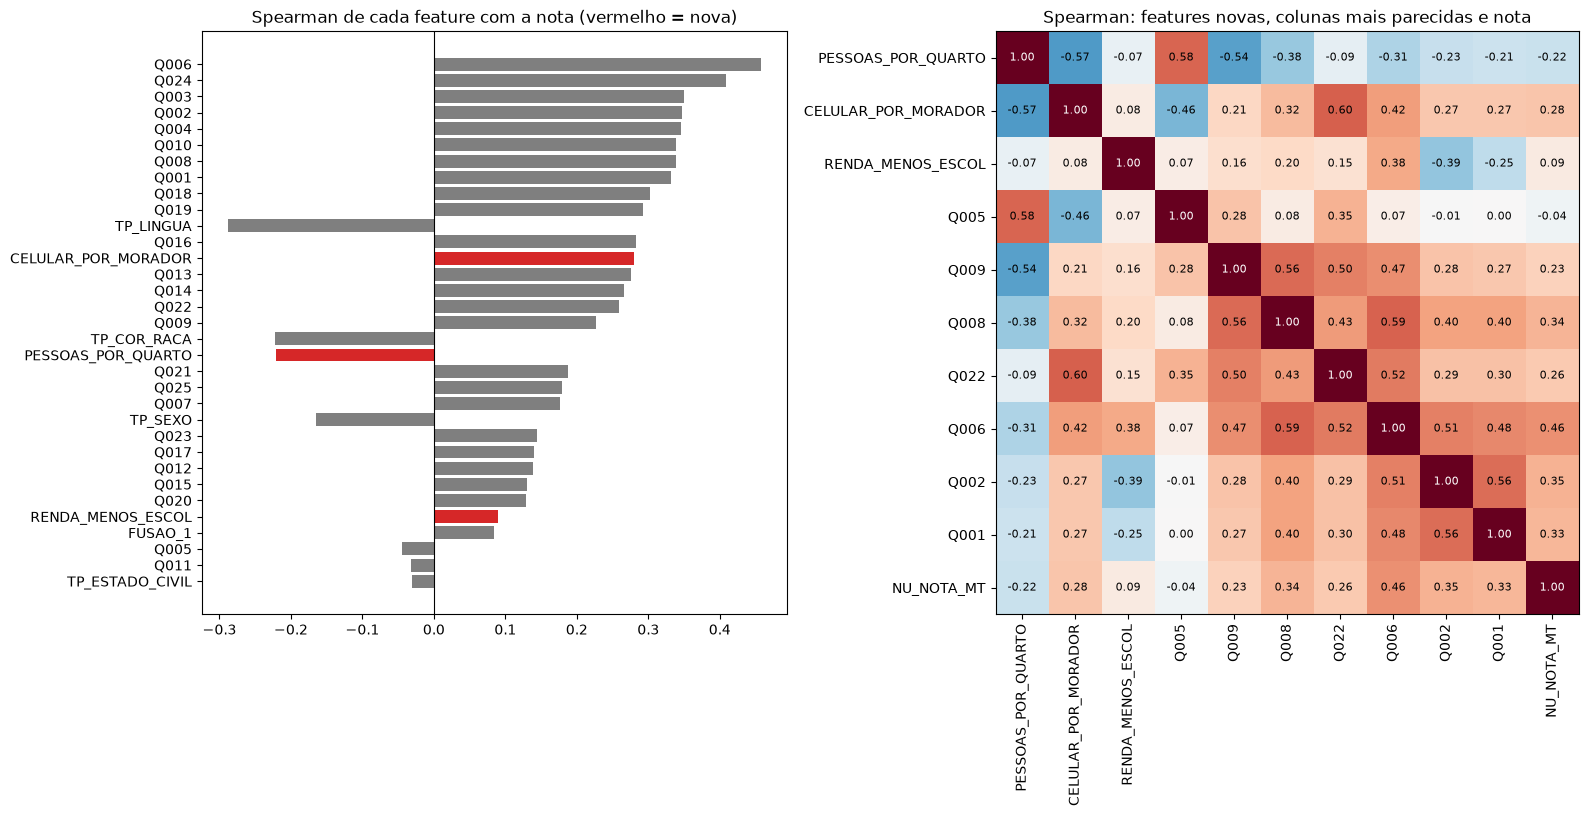

In [ ]:
# Spearman: como as 3 features novas se relacionam com a nota e com as outras colunas.
# (Spearman = correlação de ranking: 0 = nenhuma relação, 1 = sobem juntas, -1 = uma sobe e a outra desce.)
corr_f = dataset_1_feat.rank().corr()

print(f"{'feature':<22}{'ρ com a nota':>13}   as 3 colunas mais parecidas com ela (ρ)")
print("-" * 100)
parecidas = {}
for nova in NOVAS:
    top = corr_f[nova].drop([nova, ALVO] + [n for n in NOVAS if n != nova]).abs().sort_values(ascending=False).head(3)
    parecidas[nova] = list(top.index)
    txt = ", ".join(f"{c} {corr_f.loc[nova, c]:+.2f}" for c in top.index)
    print(f"{nova:<22}{corr_f.loc[nova, ALVO]:>+13.3f}   {txt}")

# redundância: |ρ| > 0,7 com alguma outra feature (mesmo limite usado na seção 8)
print("\nMaior |ρ| de cada feature nova com qualquer OUTRA feature (limite de redundância: 0,70):")
for nova in NOVAS:
    outras = corr_f[nova].drop([nova, ALVO]).abs().sort_values(ascending=False)
    print(f"   {nova:<22} {outras.iloc[0]:.3f} com {outras.index[0]:<5} ->  {'REDUNDANTE' if outras.iloc[0] > 0.7 else 'ok'}")

# gráficos
corr_nota = corr_f[ALVO].drop(ALVO).sort_values(key=abs, ascending=True)
fig, ax = plt.subplots(1, 2, figsize=(16, 8))
cores = ["tab:red" if c in NOVAS else "tab:gray" for c in corr_nota.index]
ax[0].barh(corr_nota.index, corr_nota.values, color=cores)
ax[0].set_title("Spearman de cada feature com a nota (vermelho = nova)")
ax[0].axvline(0, color="black", lw=0.8)

ordem = list(dict.fromkeys(NOVAS + [c for v in parecidas.values() for c in v] + [ALVO]))
m = corr_f.loc[ordem, ordem].values
ax[1].imshow(m, cmap="RdBu_r", vmin=-1, vmax=1)
ax[1].set_xticks(range(len(ordem)), ordem, rotation=90)
ax[1].set_yticks(range(len(ordem)), ordem)
for i in range(len(ordem)):
    for j in range(len(ordem)):
        ax[1].text(j, i, f"{m[i, j]:.2f}", ha="center", va="center", fontsize=8,
                   color="white" if abs(m[i, j]) > 0.6 else "black")
ax[1].set_title("Spearman: features novas, colunas mais parecidas e nota")
plt.tight_layout()
plt.show()


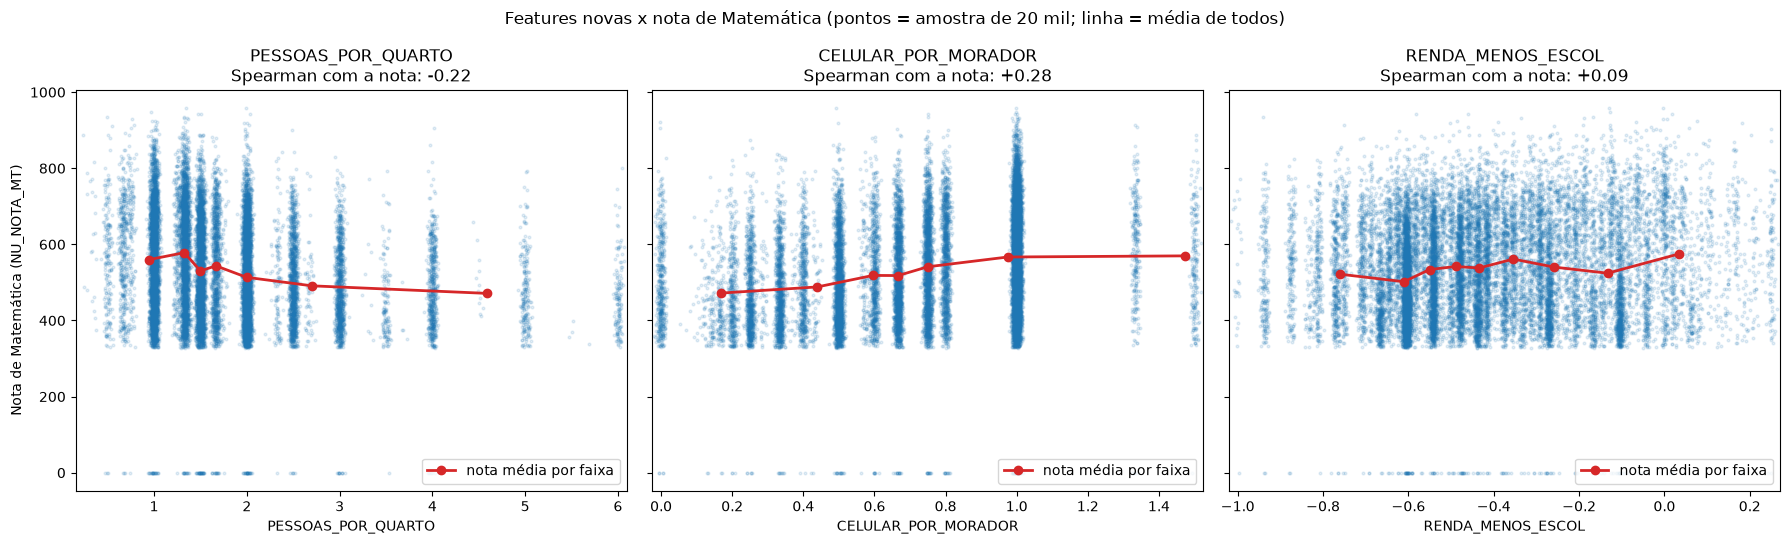

Leitura: se a linha vermelha sobe ou desce de forma clara, a feature tem relação com a nota.
Linha quase reta = pouca relação. Nuvem de pontos larga em todo lugar = a nota varia muito mesmo com a feature igual.


In [ ]:
# Dispersão (scatter) de cada feature nova contra a nota de Matemática.
# Com 2,7 milhões de pontos o gráfico viraria uma mancha, então os pontos são uma amostra de 20 mil linhas
# (só para desenhar). A linha vermelha usa TODAS as linhas: a nota média em cada faixa da feature.
# As features são discretas (poucos valores repetidos), então os pontos formam colunas; um pequeno ruído
# horizontal só espalha os pontos para dar para enxergar. O ruído não altera os dados.
rng = np.random.default_rng(42)
amostra = dataset_1_feat.sample(20_000, random_state=42)

fig, eixos = plt.subplots(1, len(NOVAS), figsize=(18, 5.5), sharey=True)
for ax, nova in zip(eixos, NOVAS):
    x_max = dataset_1_feat[nova].quantile(0.995)          # corta só o desenho: poucos casos extremos esticam o eixo
    x_min = dataset_1_feat[nova].min()
    passo = (x_max - x_min) / 60
    xs = amostra[nova].clip(upper=x_max) + rng.normal(0, passo * 0.25, len(amostra))
    ax.scatter(xs, amostra[ALVO], s=4, alpha=0.12, color="tab:blue", rasterized=True)

    # nota média por faixa (10 faixas com a mesma quantidade de pessoas), com todas as linhas
    faixas = pd.qcut(dataset_1_feat[nova], q=10, duplicates="drop")
    media = dataset_1_feat.groupby(faixas, observed=True).agg(x=(nova, "mean"), nota=(ALVO, "mean"))
    ax.plot(media["x"].clip(upper=x_max), media["nota"], color="tab:red", marker="o", lw=2, label="nota média por faixa")

    rho = corr_f.loc[nova, ALVO] if "corr_f" in globals() else dataset_1_feat[[nova, ALVO]].corr(method="spearman").iloc[0, 1]
    ax.set_title(f"{nova}\nSpearman com a nota: {rho:+.2f}")
    ax.set_xlabel(nova)
    ax.set_xlim(x_min - passo, x_max + passo)
    ax.legend(loc="lower right")
eixos[0].set_ylabel("Nota de Matemática (NU_NOTA_MT)")
plt.suptitle("Features novas x nota de Matemática (pontos = amostra de 20 mil; linha = média de todos)")
plt.tight_layout()
plt.show()

print("Leitura: se a linha vermelha sobe ou desce de forma clara, a feature tem relação com a nota.")
print("Linha quase reta = pouca relação. Nuvem de pontos larga em todo lugar = a nota varia muito mesmo com a feature igual.")

In [ ]:
# Salva o "dataset 1 + features" (o dataset 1 revisado com as 3 colunas novas). Não mexe no dataset_1_fundido.csv.
explicacao_1f = (
    "Dataset 1 + features: o dataset 1 revisado (30 features) mais 3 features criadas (hipóteses na seção 11c), sem nenhum null.\n"
    "As 3 novas são calculadas linha a linha, só com colunas da própria linha, então não vazam informação do teste.\n"
    "ATENÇÃO: o resto continua como no dataset 1 (FUSAO_1 e medianas de Q001 a Q004 com todas as linhas).\n"
    "Antes de modelar, refazer essas etapas só com o treino."
)
extra_1f = {**extra_1,
    "PESSOAS_POR_QUARTO": "Pessoas na casa (Q005) dividido pelos quartos de dormir (Q009, mínimo 1).",
    "CELULAR_POR_MORADOR": "Telefones celulares (Q022, código 0 a 4) dividido pelas pessoas na casa (Q005).",
    "RENDA_MENOS_ESCOL": "Q006/16 menos a maior escolaridade entre Q001 e Q002 dividida por 6: renda e estudo na escala 0 a 1.",
}
info_1f = salvar_dataset(dataset_1_feat, "dataset_1_features", explicacao_1f, extra_1f)

features_1f = [c for c in dataset_1_feat.columns if c != ALVO]
print(f"\nFeatures: {len(features_1f)}  ({len(features_1)} do dataset 1 + {len(NOVAS)} criadas)")
print(f"Formato:  {dataset_1_feat.shape}")
info_1f


DATASET: dataset_1_features
Dataset 1 + features: o dataset 1 revisado (30 features) mais 3 features criadas (hipóteses na seção 11c), sem nenhum null.
As 3 novas são calculadas linha a linha, só com colunas da própria linha, então não vazam informação do teste.
ATENÇÃO: o resto continua como no dataset 1 (FUSAO_1 e medianas de Q001 a Q004 com todas as linhas).
Antes de modelar, refazer essas etapas só com o treino.

Linhas:  2,692,427  (participantes com nota de Matemática)
Colunas: 34  = 29 originais + 1 fundida(s) + 0 indicadora(s) + 3 criada(s) + 0 one-hot + 1 alvo
Nulls:   nenhum
Questionário (Q001 a Q025): letras viraram números (A=0, B=1, C=2...).
Linhas na mesma ordem do arquivo ids_elegiveis.csv (NU_INSCRICAO).

Salvo em: /Users/joaoigorandrade/Documents/unifor/cienciadedados/ciencia-de-dados-unifor-projeto-2/dados/processed/dataset_1_features.csv
Tamanho:  238 MB

Features: 33  (30 do dataset 1 + 3 criadas)
Formato:  (2692427, 34)


,coluna,papel,descricao,% null,min,max
0,TP_SEXO,feature original,Sexo (M/F),0.0,0.000,1.000
1,TP_ESTADO_CIVIL,feature original,"Estado civil (0=não informado, 1=solteiro, 2=casado, 3=divorciado, 4=viúvo)",0.0,0.000,4.000
2,TP_COR_RACA,feature original,"Cor/raça (0=não declarado, 1=branca, 2=preta, 3=parda, 4=amarela, 5=indígena, 6=não dispõe)",0.0,0.000,5.000
3,TP_LINGUA,feature original,"Língua estrangeira (0=inglês, 1=espanhol)",0.0,0.000,1.000
4,Q001,feature original,"Escolaridade do pai/responsável (A=nunca estudou ... G=pós, H=não sei)",0.0,0.000,6.000
5,Q002,feature original,"Escolaridade da mãe/responsável (A=nunca estudou ... G=pós, H=não sei)",0.0,0.000,6.000
6,Q003,feature original,"Grupo de ocupação do pai (A a E, F=não sei)",0.0,0.000,4.000
7,Q004,feature original,"Grupo de ocupação da mãe (A a E, F=não sei)",0.0,0.000,4.000
8,Q005,feature original,Pessoas que moram na casa (1 a 20),0.0,1.000,20.000
9,Q006,feature original,Renda mensal da família (A=nenhuma ... Q=acima de R$ 26.400),0.0,0.000,16.000


## 12. Dataset 2 e dataset 2 + features

O dataset 2 tem **duas versões**, e só duas:

- **Dataset 2** = dataset 1 (30 features) + escola = **34 features** (`dataset_2_escola.csv`).
- **Dataset 2 + features** = dataset 1 + features (33) + a mesma escola = **37 features** (`dataset_2_features_escola.csv`).

Volta a usar as colunas do **tipo de escola**, que tinham saído (nulls na seção 4, `TP_ESCOLA` na revisão 11b). A escola vem de `TP_ESCOLA` (pública, privada),
`TP_DEPENDENCIA_ADM_ESC` (federal, estadual, municipal, privada) e `TP_LOCALIZACAO_ESC` (urbana, rural).
São nominais, então viram 8 colunas 0/1 (one-hot), com a primeira categoria como referência. Null nas colunas da escola (73%, quem já terminou o ensino médio) é a categoria
**"sem informação"** e é a referência (todas as colunas da escola ficam 0): o null carrega informação, por isso não é preenchido com mediana.
Não entram UF nem município (o município só com target encoding dentro do Pipeline, num dataset 3).

**Retirada:** o Spearman mostrou colunas redundantes entre as de escola, e as 4 colunas de dependência (`DEP_*`) saem, sem fusão:

| Coluna retirada | Motivo |
|---|---|
| `DEP_PRIVADA` | Spearman 0,88 com `ESCOLA_PRIVADA` (a mesma pessoa marcada nas duas) |
| `DEP_ESTADUAL` | 0,73 com `LOC_URBANA` e 0,68 com `ESCOLA_PUBLICA` |
| `DEP_MUNICIPAL` | só 0,2% das linhas e Spearman de −0,005 com a nota |
| `DEP_FEDERAL` | só 1,6% das linhas; sem as outras `DEP_*` viraria "federal contra todo o resto" |

Ficam 4 colunas de escola: `ESCOLA_PUBLICA`, `ESCOLA_PRIVADA`, `LOC_URBANA` e `LOC_RURAL`. Depois da retirada, nenhum par passa de 0,7.
As células de Spearman anteriores à retirada ficam como registro do "antes".

Como só mudam as 3 colunas criadas, comparar o dataset 2 com o dataset 2 + features mostra o efeito das features novas.
Mesmas regras do dataset 1: nenhum null, mesmas linhas e na mesma ordem de `ids_elegiveis.csv`, alvo `NU_NOTA_MT` na última coluna.
Rode depois da 11c: usa `dataset_1`, `dataset_1_feat`, `extra_1`, `extra_1f`, `features_1` e `features_1f`.

In [ ]:
# Dataset 2: dataset 1 + o tipo de escola (colunas que tinham saído por causa dos nulls ou da revisão 11b).
# São nominais (o número do código não é uma escala), então viram colunas 0/1 (one-hot). A primeira categoria é a de
# referência e não ganha coluna (equivale a drop="first"). As categorias estão escritas à mão: nenhum dado define colunas.
# `df` (seção 5) tem as mesmas linhas, na mesma ordem, do dataset 1: conferimos antes de juntar.
assert len(df) == len(dataset_1), f"df tem {len(df):,} linhas e dataset_1 tem {len(dataset_1):,}."
assert (df["Q005"].values == dataset_1["Q005"].values).all(), "linhas fora de ordem entre df e dataset_1."

esc, dep, loc = df["TP_ESCOLA"], df["TP_DEPENDENCIA_ADM_ESC"], df["TP_LOCALIZACAO_ESC"]
assert esc.isin([1, 2, 3]).all() and dep.dropna().isin([1, 2, 3, 4]).all() and loc.dropna().isin([1, 2]).all(), "código novo."

# null em dep/loc = "sem informação" (quem já terminou o ensino médio): é a categoria de referência, todas as colunas 0.
dummies = pd.DataFrame({
    "ESCOLA_PUBLICA": esc == 2, "ESCOLA_PRIVADA": esc == 3,                      # referência: 1 = não respondeu
    "DEP_FEDERAL": dep == 1, "DEP_ESTADUAL": dep == 2,                           # referência: sem informação
    "DEP_MUNICIPAL": dep == 3, "DEP_PRIVADA": dep == 4,
    "LOC_URBANA": loc == 1, "LOC_RURAL": loc == 2,                               # referência: sem informação
}).astype("int8")
DUMMIES = list(dummies.columns)

def juntar_dummies(base):
    saida = pd.concat([base.drop(columns=ALVO), dummies], axis=1)
    saida[ALVO] = base[ALVO].values
    return saida

dataset_2 = juntar_dummies(dataset_1)
dataset_2_feat = juntar_dummies(dataset_1_feat)

# conferência: quanto cada categoria pesa e a nota média de quem está nela
ref = {"TP_ESCOLA": "não respondeu", "TP_DEPENDENCIA_ADM_ESC": "sem informação", "TP_LOCALIZACAO_ESC": "sem informação"}
linhas = [("ESCOLA (referência: não respondeu)", (esc == 1))] + [(c, dataset_2[c] == 1) for c in DUMMIES[:2]]
linhas += [("DEP/LOC (referência: sem informação)", dep.isna() & loc.isna())] + [(c, dataset_2[c] == 1) for c in DUMMIES[2:]]
resumo_d = pd.DataFrame({"% das linhas": [round(m.mean() * 100, 1) for _, m in linhas],
                         "nota média": [round(dataset_2.loc[m, ALVO].mean()) for _, m in linhas]},
                        index=[n for n, _ in linhas])
print(f"dataset_2:          {dataset_2.shape}  ({dataset_2.shape[1] - 1} features = {dataset_1.shape[1] - 1} do dataset 1 + {len(DUMMIES)} colunas de escola)")
print(f"dataset_2 + feat.:  {dataset_2_feat.shape}  ({dataset_2_feat.shape[1] - 1} features = {dataset_1_feat.shape[1] - 1} do dataset 1 + features + {len(DUMMIES)})")
print("Nulls restantes:", int(dataset_2.isna().sum().sum() + dataset_2_feat.isna().sum().sum()))
resumo_d


dataset_2:          (2692427, 39)  (38 features = 30 do dataset 1 + 8 colunas de escola)
dataset_2 + feat.:  (2692427, 42)  (41 features = 33 do dataset 1 + features + 8)
Nulls restantes: 0


,% das linhas,nota média
ESCOLA (referência: não respondeu),60.8,536
ESCOLA_PUBLICA,31.0,504
ESCOLA_PRIVADA,8.2,631
DEP/LOC (referência: sem informação),73.1,529
DEP_FEDERAL,1.6,603
DEP_ESTADUAL,17.1,502
DEP_MUNICIPAL,0.2,519
DEP_PRIVADA,8.0,632
LOC_URBANA,26.0,549
LOC_RURAL,0.9,496


Spearman com a nota:
ESCOLA_PRIVADA    0.217
DEP_PRIVADA       0.217
ESCOLA_PUBLICA   -0.150
DEP_ESTADUAL     -0.107
DEP_FEDERAL       0.070
LOC_URBANA        0.068
LOC_RURAL        -0.028
DEP_MUNICIPAL    -0.005

Redundância (|ρ| > 0,70) entre as colunas de escola e todas as outras features:
   ESCOLA_PUBLICA  0.677 com DEP_ESTADUAL    ->  ok
   ESCOLA_PRIVADA  0.880 com DEP_PRIVADA     ->  REDUNDANTE
   DEP_FEDERAL     0.193 com ESCOLA_PUBLICA  ->  ok
   DEP_ESTADUAL    0.727 com LOC_URBANA      ->  REDUNDANTE
   DEP_MUNICIPAL   0.069 com LOC_URBANA      ->  ok
   DEP_PRIVADA     0.880 com ESCOLA_PRIVADA  ->  REDUNDANTE
   LOC_URBANA      0.727 com DEP_ESTADUAL    ->  REDUNDANTE
   LOC_RURAL       0.152 com DEP_FEDERAL     ->  ok


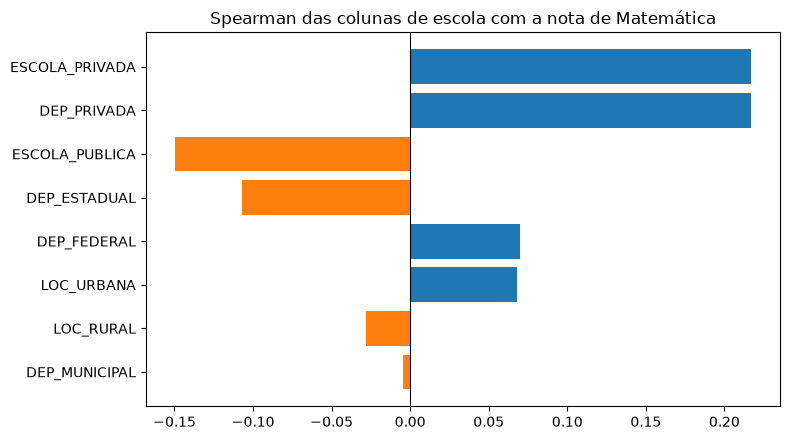

In [ ]:
# Spearman das 8 colunas de escola com a nota. Cada coluna é 0/1, então o Spearman aqui mede "estar nessa categoria
# sobe ou desce a nota?" em relação a todos os outros. A coluna mais alta mostra qual categoria de escola mais pesa.
corr_d = dataset_2_feat.rank().corr()
de_escola = corr_d.loc[DUMMIES, ALVO].sort_values(key=abs, ascending=False)
print("Spearman com a nota:")
print(de_escola.round(3).to_string())

print("\nRedundância (|ρ| > 0,70) entre as colunas de escola e todas as outras features:")
for col in DUMMIES:
    outra = corr_d[col].drop([col, ALVO]).abs().sort_values(ascending=False)
    print(f"   {col:<15} {outra.iloc[0]:.3f} com {outra.index[0]:<15} ->  {'REDUNDANTE' if outra.iloc[0] > 0.7 else 'ok'}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(de_escola.index[::-1], de_escola.values[::-1], color=["tab:blue" if v >= 0 else "tab:orange" for v in de_escola.values[::-1]])
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Spearman das colunas de escola com a nota de Matemática")
plt.tight_layout()
plt.show()


In [ ]:
# Spearman de cada feature do dataset 2 com a nota (mesmo gráfico das seções 8 e 10).
# Usa a matriz `corr_d` da célula do Spearman acima (calculada com o dataset 2 + features); o Spearman entre duas colunas
# não muda por existirem outras, então o dataset 2 é só um pedaço dela.
cols_2 = list(dataset_2.columns)
corr_2 = corr_d.loc[cols_2, cols_2]
corr_alvo_2 = corr_2[ALVO].drop(ALVO)

dados = corr_alvo_2.sort_values().reset_index()
dados.columns = ["feature", "spearman"]

fig = px.bar(
    dados, x="spearman", y="feature", orientation="h",
    color="spearman", color_continuous_scale="RdBu_r", range_color=[-1, 1],
    title="Spearman de cada feature do dataset 2 com NU_NOTA_MT",
)
fig.update_layout(width=800, height=900)
fig.show()


In [ ]:
fig = px.imshow(
    corr_2.round(2),
    color_continuous_scale="RdBu_r", zmin=-1, zmax=1, aspect="auto",
    title="Spearman entre as colunas do dataset 2",
)
fig.update_layout(width=1000, height=900)
fig.show()


In [ ]:
# Os mesmos dois gráficos para o dataset 2 + features (as 3 colunas criadas aparecem em vermelho no gráfico de barras).
cols_2f = list(dataset_2_feat.columns)
corr_2f = corr_d.loc[cols_2f, cols_2f]

dados = corr_2f[ALVO].drop(ALVO).sort_values().reset_index()
dados.columns = ["feature", "spearman"]
dados["tipo"] = ["criada" if f in NOVAS else "escola" if f in DUMMIES else "dataset 1" for f in dados["feature"]]

fig = px.bar(
    dados, x="spearman", y="feature", orientation="h", color="tipo",
    color_discrete_map={"criada": "crimson", "escola": "royalblue", "dataset 1": "lightgray"},
    title="Spearman de cada feature do dataset 2 + features com NU_NOTA_MT",
)
fig.update_layout(width=850, height=1000)
fig.show()

fig = px.imshow(
    corr_2f.round(2),
    color_continuous_scale="RdBu_r", zmin=-1, zmax=1, aspect="auto",
    title="Spearman entre as colunas do dataset 2 + features",
)
fig.update_layout(width=1050, height=950)
fig.show()


In [ ]:
# Pares de colunas muito parecidas no dataset 2 + features (inclui todos os pares do dataset 2).
LIMITE_P = 0.7
c = corr_2f.drop(index=ALVO, columns=ALVO)
tri = c.where(np.triu(np.ones(c.shape, dtype=bool), k=1))
pares_2 = tri.stack().dropna().rename("spearman").reset_index()
pares_2.columns = ["coluna_1", "coluna_2", "spearman"]
pares_2 = pares_2[pares_2["spearman"].abs() > LIMITE_P].sort_values("spearman", key=abs, ascending=False)
pares_2["envolve"] = ["criada" if (a in NOVAS or b in NOVAS) else "escola" if (a in DUMMIES or b in DUMMIES) else "dataset 1"
                      for a, b in zip(pares_2["coluna_1"], pares_2["coluna_2"])]

print(f"Pares com |Spearman| > {LIMITE_P} no dataset 2 + features: {len(pares_2)}")
print("(os do dataset 1 já foram vistos na seção 9; 'escola' e 'criada' são os novos)")
pares_2.round(3).reset_index(drop=True)


Pares com |Spearman| > 0.7 no dataset 2 + features: 2
(os do dataset 1 já foram vistos na seção 9; 'escola' e 'criada' são os novos)


,coluna_1,coluna_2,spearman,envolve
0,ESCOLA_PRIVADA,DEP_PRIVADA,0.880,escola
1,DEP_ESTADUAL,LOC_URBANA,0.727,escola


In [ ]:
# Dataset 2: tira as 4 colunas de dependência da escola, DEP_* (sem fusão, só retirar). Ficam ESCOLA_* e LOC_*.
#   DEP_PRIVADA   : |Spearman| 0,88 com ESCOLA_PRIVADA (a mesma pessoa marcada nas duas).
#   DEP_ESTADUAL  : 0,73 com LOC_URBANA e 0,68 com ESCOLA_PUBLICA.
#   DEP_MUNICIPAL : só 0,2% das linhas e Spearman de -0,005 com a nota.
#   DEP_FEDERAL   : só 1,6% das linhas (nota média 603, mas Spearman de apenas +0,07). Sai junto: sem as outras DEP, viraria "federal x todo o resto".
# Os datasets antes da retirada (dataset_2, dataset_2_feat) continuam na memória.
DROPAR = ["DEP_FEDERAL", "DEP_ESTADUAL", "DEP_MUNICIPAL", "DEP_PRIVADA"]

dataset_2_final = dataset_2.drop(columns=DROPAR)
dataset_2_feat_final = dataset_2_feat.drop(columns=DROPAR)
DUMMIES_FINAL = [c for c in DUMMIES if c not in DROPAR]            # one-hot que ficaram

print("Colunas retiradas:", DROPAR)
print("Escola que ficou (0/1):", DUMMIES_FINAL)
print(f"\ndataset_2 final:          {dataset_2_final.shape}   ({dataset_2_final.shape[1] - 1} features; antes {dataset_2.shape[1] - 1})")
print(f"dataset_2 + feat. final:  {dataset_2_feat_final.shape}   ({dataset_2_feat_final.shape[1] - 1} features; antes {dataset_2_feat.shape[1] - 1})")
print("Nulls restantes:", int(dataset_2_final.isna().sum().sum() + dataset_2_feat_final.isna().sum().sum()))


In [ ]:
# Spearman depois de retirar as colunas DEP_* (lista DROPAR).
# O Spearman entre duas colunas não muda por outras terem saído, então a matriz é a `corr_d` sem essas 2 linhas e colunas.
cols_2 = list(dataset_2_final.columns)
cols_2f = list(dataset_2_feat_final.columns)
corr_2 = corr_d.loc[cols_2, cols_2]
corr_2f = corr_d.loc[cols_2f, cols_2f]

print("Spearman com a nota das colunas de escola que ficaram:")
print(corr_2f.loc[DUMMIES_FINAL, ALVO].sort_values(key=abs, ascending=False).round(3).to_string())

c = corr_2f.drop(index=ALVO, columns=ALVO)
tri = c.where(np.triu(np.ones(c.shape, dtype=bool), k=1))
sobrou = tri.stack().dropna().rename("spearman").reset_index()
sobrou.columns = ["coluna_1", "coluna_2", "spearman"]
print("\nMaiores pares entre as features (dataset 2 + features):")
print(sobrou.reindex(sobrou["spearman"].abs().sort_values(ascending=False).index).head(8).round(3).to_string(index=False))
print(f"\nPares com |Spearman| > 0,7: {int((sobrou['spearman'].abs() > 0.7).sum())}")
print("Escola x escola, o que sobrou:")
esc = sobrou[sobrou["coluna_1"].isin(DUMMIES_FINAL) & sobrou["coluna_2"].isin(DUMMIES_FINAL)]
print(esc.reindex(esc["spearman"].abs().sort_values(ascending=False).index).round(3).to_string(index=False))

def barras(corr_m, titulo, altura):
    dados = corr_m[ALVO].drop(ALVO).sort_values().reset_index()
    dados.columns = ["feature", "spearman"]
    dados["tipo"] = ["criada" if f in NOVAS else "escola" if f in DUMMIES_FINAL else "dataset 1" for f in dados["feature"]]
    fig = px.bar(dados, x="spearman", y="feature", orientation="h", color="tipo",
                 color_discrete_map={"criada": "crimson", "escola": "royalblue", "dataset 1": "lightgray"}, title=titulo)
    fig.update_layout(width=850, height=altura)
    fig.show()

def heatmap(corr_m, titulo, lado):
    fig = px.imshow(corr_m.round(2), color_continuous_scale="RdBu_r", zmin=-1, zmax=1, aspect="auto", title=titulo)
    fig.update_layout(width=lado + 100, height=lado)
    fig.show()

barras(corr_2, "Spearman de cada feature do dataset 2 com NU_NOTA_MT (sem as DEP_*)", 900)
heatmap(corr_2, "Spearman entre as colunas do dataset 2 (sem as DEP_*)", 900)
barras(corr_2f, "Spearman de cada feature do dataset 2 + features com NU_NOTA_MT (sem as DEP_*)", 950)
heatmap(corr_2f, "Spearman entre as colunas do dataset 2 + features (sem as DEP_*)", 950)


In [ ]:
# Salva o dataset 2 (dataset 1 + escola, sem as DEP_*).
explicacao_2 = (
    "Dataset 2: o dataset 1 revisado (30 features) mais 4 colunas 0/1 de escola, sem nenhum null.\n"
    "TP_ESCOLA (ESCOLA_PUBLICA, ESCOLA_PRIVADA; referência: não respondeu) e TP_LOCALIZACAO_ESC (LOC_URBANA, LOC_RURAL).\n"
    "Saíram as 4 colunas de dependência da escola (DEP_*): DEP_PRIVADA tinha |Spearman| 0,88 com ESCOLA_PRIVADA e DEP_ESTADUAL 0,73 com LOC_URBANA.\n"
    "Null nas colunas da escola (73%, quem já terminou o ensino médio) = \"sem informação\" = referência (tudo 0). Sem UF nem município.\n"
    "ATENÇÃO: como no dataset 1, FUSAO_1 e as medianas de Q001 a Q004 usaram todas as linhas; refazer só com o treino.\n"
    "As colunas 0/1 não são padronizadas aqui: o StandardScaler (modelos lineares, SVR, PCA) vai dentro do Pipeline."
)
extra_2 = {**extra_1,
    "ESCOLA_PUBLICA": "1 = escola pública (TP_ESCOLA = 2). Referência: não respondeu (TP_ESCOLA = 1).",
    "ESCOLA_PRIVADA": "1 = escola privada (TP_ESCOLA = 3).",
    "LOC_URBANA": "1 = escola urbana (TP_LOCALIZACAO_ESC = 1). Referência: sem informação (null).",
    "LOC_RURAL": "1 = escola rural (TP_LOCALIZACAO_ESC = 2).",
}
info_2 = salvar_dataset(dataset_2_final, "dataset_2_escola", explicacao_2, extra_2)

features_2 = [c for c in dataset_2_final.columns if c != ALVO]
print(f"\nFeatures: {len(features_2)}  ({len(features_1)} do dataset 1 + {len(DUMMIES_FINAL)} de escola)")
info_2


In [ ]:
# Salva o dataset 2 + features (dataset 1 + features + escola, sem as DEP_*).
explicacao_2f = (
    "Dataset 2 + features: o dataset 1 + features (33) mais as 4 colunas 0/1 de escola do dataset 2, sem nenhum null.\n"
    "Tem as 3 features criadas na seção 11c (PESSOAS_POR_QUARTO, CELULAR_POR_MORADOR, RENDA_MENOS_ESCOL) e a escola do dataset 2.\n"
    "Só muda em relação ao dataset 2 as 3 colunas criadas, então a comparação entre os dois isola o efeito das features novas.\n"
    "ATENÇÃO: FUSAO_1 e as medianas de Q001 a Q004 usaram todas as linhas; refazer só com o treino."
)
extra_2f = {**extra_1f, **{k: v for k, v in extra_2.items() if k in dataset_2_feat_final.columns and k not in extra_1f}}
info_2f = salvar_dataset(dataset_2_feat_final, "dataset_2_features_escola", explicacao_2f, extra_2f)

features_2f = [c for c in dataset_2_feat_final.columns if c != ALVO]
print(f"\nFeatures: {len(features_2f)}  ({len(features_1f)} do dataset 1 + features + {len(DUMMIES_FINAL)} de escola)")
print("Datasets salvos em dados/processed/: dataset_1_fundido, dataset_1_features, dataset_2_escola, dataset_2_features_escola")
info_2f
